## 1. Imports & display settings


In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["axes.axisbelow"] = True


## 2. Load the raw dataset


In [2]:
candidates = [Path("Online Retail.xlsx"), Path("RFM/Online Retail.xlsx")]
path = next((p for p in candidates if p.exists()), None)
if path is None:
    raise FileNotFoundError("Could not find 'Online Retail.xlsx' in the current directory or the RFM folder.")

df = pd.read_excel(path, parse_dates=["InvoiceDate"])
print(f"Loaded {path} with {len(df):,} rows and {len(df.columns)} columns.")

df.head()

Loaded Online Retail.xlsx with 541,909 rows and 8 columns.


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom


## 3. Initial data audit


In [3]:
print("Shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("Negative quantity:", (df["Quantity"] < 0).sum())
print("Zero price:", (df["UnitPrice"] == 0).sum())
print("Negative price:", (df["UnitPrice"] < 0).sum())

missing = pd.DataFrame({
    "Missing": df.isna().sum(),
    "Missing_%": df.isna().mean() * 100
})

display(missing[missing["Missing"] > 0].round(2))

Shape: (541909, 8)


Duplicate rows: 5268
Negative quantity: 10624
Zero price: 2515
Negative price: 2


,Missing,Missing_%
Description,1454,0.27
CustomerID,135080,24.93


In [4]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,"541,909.00","25,900.00","573,585.00","1,114.00",NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,"541,909.00",NaN,NaN,NaN,9.55,"-80,995.00",1.00,3.00,10.00,"80,995.00",218.08
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,"541,909.00",NaN,NaN,NaN,4.61,"-11,062.06",1.25,2.08,4.13,"38,970.00",96.76
CustomerID,"406,829.00",NaN,NaN,NaN,"15,287.69","12,346.00","13,953.00","15,152.00","16,791.00","18,287.00","1,713.60"
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


We know the size, missing-value pattern, duplicates, negative quantities, and price anomalies before changing the data.


## 4. Type correction & text standardization


In [5]:
# Keep missing values as missing while converting text columns.
df["InvoiceNo"] = df["InvoiceNo"].astype("string").str.strip()
df["StockCode"] = df["StockCode"].astype("string").str.strip().str.upper()
df["Country"] = df["Country"].astype("string").str.strip()

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce")
df["CustomerID"] = pd.to_numeric(df["CustomerID"], errors="coerce").astype("Int64").astype("string")

# Standardize Description without changing the actual product meaning.
df["Description"] = (
    df["Description"]
    .astype("string")
    .str.strip()
    .str.upper()
    .str.replace(r"\s+", " ", regex=True)
    .str.replace(r"^\?+|\?+$", "", regex=True)
    .str.strip()
)

# Empty descriptions created after removing question marks become missing again.
df["Description"] = df["Description"].replace("", pd.NA)

# Only clear spelling variants are standardized.
df["Description"] = df["Description"].replace({
    "DAMAGES": "DAMAGED",
    "DAMAGE": "DAMAGED"
})

# One timestamp per invoice: 43 invoices have lines stamped 1 minute apart (same checkout).
# Done before duplicate detection so near-identical lines are not missed.
df["InvoiceDate"] = df.groupby("InvoiceNo")["InvoiceDate"].transform("min")

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  string        
 1   StockCode    541909 non-null  string        
 2   Description  540400 non-null  string        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  string        
 7   Country      541909 non-null  string        
dtypes: datetime64[us](1), float64(1), int64(1), string(5)
memory usage: 33.1 MB


- IDs are treated as identifiers, not numeric measurements.
- `InvoiceDate` is a real datetime.
- Extra spaces and case differences in `Description` are standardized.
- Only obvious equivalent dirty labels are merged.


## 5. Missing `Description` — infer only when reliable


In [6]:
miss_desc = df[df["Description"].isna()]

print("Missing Description rows:", len(miss_desc))
print("Price = 0 share:", (miss_desc["UnitPrice"] == 0).mean())
print("Missing CustomerID share:", miss_desc["CustomerID"].isna().mean())

Missing Description rows: 1509
Price = 0 share: 1.0
Missing CustomerID share: 1.0


In [7]:
# Reliable reference: positive-quantity, positive-price transactions with a known description.
good = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0) &
    df["Description"].notna()
]

# Most common known description for each StockCode.
desc_map = good.groupby("StockCode")["Description"].agg(
    lambda x: x.value_counts().index[0]
)

# Fill missing descriptions only when the same StockCode gives us evidence.
df["Description"] = df["Description"].fillna(
    df["StockCode"].map(desc_map)
)

print("Description still missing:", df["Description"].isna().sum())

Description still missing: 115


Remaining missing descriptions are **not guessed**. They will be removed later only if they survive the anomaly rules and still cannot be explained.


## 6. Missing `CustomerID` — test whether it can be recovered


In [8]:
by_invoice = (
    df.assign(MissingCustomer=df["CustomerID"].isna())
    .groupby("InvoiceNo")["MissingCustomer"]
    .agg(["sum", "size"])
)

partial_missing = (
    (by_invoice["sum"] > 0) &
    (by_invoice["sum"] < by_invoice["size"])
).sum()

all_missing = (by_invoice["sum"] == by_invoice["size"]).sum()

print("Invoices with only some CustomerID missing:", partial_missing)
print("Invoices with all CustomerID missing:", all_missing)

Invoices with only some CustomerID missing: 0
Invoices with all CustomerID missing: 3710


**Decision:** do not invent a CustomerID. If an invoice has no known customer anywhere, there is no reliable customer-level inference.

- These rows remain useful for store-level sales EDA.
- They are excluded only from customer-level features and RFM.


## 7. Drop unusable core records


In [9]:
core_columns = [
    "InvoiceNo", "StockCode", "InvoiceDate",
    "Quantity", "UnitPrice", "Country"
]

bad_core = df[core_columns].isna().any(axis=1)

print("Rows with unusable core fields:", bad_core.sum())

df = df[~bad_core].copy()

Rows with unusable core fields:

 0


These fields define the transaction itself. If one of them is missing and no reliable inference exists, the row cannot support revenue, time, product, or geography analysis.


## 8. Transaction anomaly flags — classify before removing


In [10]:
service_codes = [
    "POST", "DOT", "M", "C2", "D", "S", "B",
    "AMAZONFEE", "CRUK", "BANK CHARGES", "PADS"
]

admin_codes = [
    "AMAZONFEE", "CRUK", "BANK CHARGES", "B"
]

df["IsDuplicate"] = df.duplicated([
    "InvoiceNo", "StockCode", "Description", "Quantity",
    "InvoiceDate", "UnitPrice", "CustomerID", "Country"
])

df["IsService"] = (
    df["StockCode"].isin(service_codes) |
    df["StockCode"].str.startswith("GIFT_", na=False)
)

df["IsAdmin"] = df["StockCode"].isin(admin_codes)
df["IsZeroPrice"] = df["UnitPrice"] == 0
df["LineRevenue"] = df["Quantity"] * df["UnitPrice"]

In [11]:
# One clear reason per excluded row.
df["Reason"] = np.select(
    [
        df["IsDuplicate"],
        df["InvoiceNo"].str.startswith("A", na=False) | (df["UnitPrice"] < 0),
        df["IsAdmin"],
        df["IsZeroPrice"] & df["CustomerID"].isna(),
        df["IsZeroPrice"],
        (df["Quantity"] < 0) & ~df["InvoiceNo"].str.startswith("C", na=False),
        df["InvoiceNo"].str.startswith("C", na=False) & (df["Quantity"] >= 0),
        df["Quantity"] == 0,
        df["Description"].isna()
    ],
    [
        "duplicate",
        "bad_debt",
        "admin_charge",
        "stock_adjustment",
        "giveaway",
        "non_cancel_negative_qty",
        "invalid_cancellation",
        "zero_quantity",
        "unresolved_description"
    ],
    default=""
)

excluded = df[df["Reason"] != ""].copy()

excluded_summary = excluded.groupby("Reason").agg(
    Rows=("InvoiceNo", "size"),
    Revenue=("LineRevenue", "sum")
).sort_values("Rows", ascending=False)

display(excluded_summary)

,Rows,Revenue
Reason,,
duplicate,5269,"21,744.88"
stock_adjustment,2470,0.00
admin_charge,87,"-236,629.57"
giveaway,40,0.00
bad_debt,3,"-11,062.06"


**Important:** service codes are not blindly deleted.

- Clear company/admin charges are excluded.
- Customer-linked postage, discounts, manual lines, and gift-related lines remain available for customer net value.
- All service codes are excluded later from **product ranking** so services are not treated as merchandise.


## 9. Validate negative quantities before building `clean`


In [12]:
neg_non_cancel = df[
    (df["Quantity"] < 0) &
    ~df["InvoiceNo"].str.startswith("C", na=False)
]

print("Negative quantity, not C rows:", len(neg_non_cancel))
print("Missing CustomerID share:", neg_non_cancel["CustomerID"].isna().mean())
print("Zero-price share:", (neg_non_cancel["UnitPrice"] == 0).mean())

display(neg_non_cancel["Description"].value_counts().head(12))

Negative quantity, not C rows: 1336
Missing CustomerID share: 1.0
Zero-price share: 1.0


Description
CHECK                        123
DAMAGED                      109
SOLD AS SET ON DOTCOM         20
MISSING                       11
THROWN AWAY                    9
UNSALEABLE, DESTROYED.         9
WET DAMAGED                    5
EBAY                           5
LOST                           4
SMASHED                        4
HEART T-LIGHT HOLDER           3
KEEP OUT BOYS DOOR HANGER      3
Name: count, dtype: Int64

This check separates customer cancellations from inventory/administrative adjustments instead of deleting every negative quantity blindly.


## 10. Build the cleaned transaction table


In [13]:
clean = df[df["Reason"] == ""].copy().reset_index(drop=True)

clean["LineType"] = np.where(
    clean["InvoiceNo"].str.startswith("C", na=False),
    "Return",
    "Sale"
)

# Orders placed and cancelled within hours (74,215 and 80,995 units) net to zero.
# Flag them so they do not fake gross sales, returns, top products, or basket sizes.
big = clean[clean["Quantity"].abs() >= 10000]
net_units = big.groupby(["CustomerID", "StockCode"])["Quantity"].transform("sum")
clean["ExtremeReversed"] = False
clean.loc[big.index[net_units == 0], "ExtremeReversed"] = True
print("Reversed mega-order lines flagged:", clean["ExtremeReversed"].sum())

# Final consistency checks.
assert clean["Description"].notna().all()
assert (clean["UnitPrice"] > 0).all()
assert (clean.loc[clean["LineType"] == "Sale", "Quantity"] > 0).all()
assert (clean.loc[clean["LineType"] == "Return", "Quantity"] < 0).all()

print("Raw shape  :", df.shape)
print("Clean shape:", clean.shape)
print("Removed rows:", len(df) - len(clean))

Reversed mega-order lines flagged: 4
Raw shape  : (541909, 14)
Clean shape: (534040, 16)
Removed rows: 7869


### Match returns to the original purchase

Returns are real events, so they are kept. Each return by a known customer is matched to that customer's latest earlier purchase of the same product, so revenue is netted with a traceable original invoice.

In [14]:
sale_lines = clean[(clean["LineType"] == "Sale") & clean["CustomerID"].notna()]
sale_lines = sale_lines[["CustomerID", "StockCode", "InvoiceDate", "InvoiceNo"]].rename(
    columns={"InvoiceDate": "SaleDate", "InvoiceNo": "OrigInvoice"}).sort_values("SaleDate")

return_lines = clean[(clean["LineType"] == "Return") & clean["CustomerID"].notna()].reset_index().sort_values("InvoiceDate")
matched = pd.merge_asof(return_lines, sale_lines, left_on="InvoiceDate", right_on="SaleDate", by=["CustomerID", "StockCode"])

clean["OrigInvoice"] = None
clean.loc[matched["index"], "OrigInvoice"] = matched["OrigInvoice"].values
clean["ReturnMatched"] = clean["OrigInvoice"].notna()

r = clean[clean["LineType"] == "Return"]
print("Return lines:", len(r))
print("Matched to an earlier purchase:", f"{r['ReturnMatched'].mean():.1%}")
print("Guest returns (no CustomerID, cannot be matched):", r["CustomerID"].isna().sum())

Return lines: 9178
Matched to an earlier purchase: 82.5%
Guest returns (no CustomerID, cannot be matched): 322


## 11. Transaction-level feature engineering


In [15]:
clean["TotalLineRevenue"] = clean["Quantity"] * clean["UnitPrice"]
clean["HasCustomer"] = clean["CustomerID"].notna()
clean["Is_UK"] = (clean["Country"] == "United Kingdom").astype(int)
clean["IsProductLine"] = ~clean["IsService"]
clean["IsReturn"] = (clean["LineType"] == "Return").astype(int)

clean["Year"] = clean["InvoiceDate"].dt.year
clean["Month"] = clean["InvoiceDate"].dt.month
clean["Quarter"] = clean["InvoiceDate"].dt.quarter
clean["YearMonth"] = clean["InvoiceDate"].dt.to_period("M").astype(str)
clean["DayOfWeek"] = clean["InvoiceDate"].dt.day_name()
clean["Hour"] = clean["InvoiceDate"].dt.hour

# One stable product name per StockCode based on the most common positive-sale description.
product_name_map = (
    clean[(clean["LineType"] == "Sale") & clean["IsProductLine"]]
    .groupby("StockCode")["Description"]
    .agg(lambda x: x.value_counts().index[0])
)

clean["ProductName"] = clean["StockCode"].map(product_name_map).fillna(clean["Description"])

clean.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,IsDuplicate,IsService,IsAdmin,IsZeroPrice,LineRevenue,Reason,LineType,ExtremeReversed,OrigInvoice,ReturnMatched,TotalLineRevenue,HasCustomer,Is_UK,IsProductLine,IsReturn,Year,Month,Quarter,YearMonth,DayOfWeek,Hour,ProductName
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,False,False,False,False,15.30,,Sale,False,None,False,15.30,True,1,True,0,2010,12,4,2010-12,Wednesday,8,WHITE HANGING HEART T-LIGHT HOLDER
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False,False,False,False,20.34,,Sale,False,None,False,20.34,True,1,True,0,2010,12,4,2010-12,Wednesday,8,WHITE METAL LANTERN
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,False,False,False,False,22.00,,Sale,False,None,False,22.00,True,1,True,0,2010,12,4,2010-12,Wednesday,8,CREAM CUPID HEARTS COAT HANGER
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False,False,False,False,20.34,,Sale,False,None,False,20.34,True,1,True,0,2010,12,4,2010-12,Wednesday,8,KNITTED UNION FLAG HOT WATER BOTTLE
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,False,False,False,False,20.34,,Sale,False,None,False,20.34,True,1,True,0,2010,12,4,2010-12,Wednesday,8,RED WOOLLY HOTTIE WHITE HEART.


The cleaned table now supports time, geography, product, return, guest-customer, and revenue analysis.


## 12. Final quality checks


In [16]:
required_clean = [
    "InvoiceNo", "StockCode", "Description", "Quantity",
    "InvoiceDate", "UnitPrice", "Country", "TotalLineRevenue"
]

assert clean[required_clean].notna().all().all()

print("Clean duplicates:", clean.duplicated().sum())
print("Clean missing descriptions:", clean["Description"].isna().sum())
print("Guest rows kept for store EDA:", clean["CustomerID"].isna().sum())
print("Sale rows:", (clean["LineType"] == "Sale").sum())
print("Return rows:", (clean["LineType"] == "Return").sum())

Clean duplicates: 0
Clean missing descriptions: 0
Guest rows kept for store EDA: 132505
Sale rows: 524862
Return rows: 9178


# 13. EDA — Business-first analysis

The EDA answers business questions before segmentation. Each section includes a direct **Insight** and a **Follow-up action** so the charts support business decisions instead of only describing the data.


In [17]:
# EDA base: reversed mega-orders removed (net zero, kept and flagged in the clean table).
eda = clean[~clean["ExtremeReversed"]].copy()

insights = []
def note(n, finding, action):
    insights.append({"#": n, "Insight": finding, "Follow-up": action})
    print(f"Insight {n}: {finding}")
    print(f"Follow-up: {action}")

sales = eda[eda["LineType"] == "Sale"].copy()
returns = eda[eda["LineType"] == "Return"].copy()

# Merchandise only for product analysis.
product_lines = eda[eda["IsProductLine"]].copy()
product_sales = sales[sales["IsProductLine"]].copy()
product_returns = returns[returns["IsProductLine"]].copy()

# Known customers only for customer-level analysis.
customer_sales = sales[sales["HasCustomer"]].copy()
customer_lines = eda[eda["HasCustomer"]].copy()

print("EDA rows:", len(eda))
print("Sales rows:", len(sales))
print("Return rows:", len(returns))


EDA rows: 534036
Sales rows: 524860
Return rows: 9176


## 14. Executive KPI snapshot


In [18]:
gross_sales_value = sales["TotalLineRevenue"].sum()
return_value = -returns["TotalLineRevenue"].sum()
net_revenue = eda["TotalLineRevenue"].sum()
sale_invoices = sales["InvoiceNo"].nunique()
known_customers = customer_sales["CustomerID"].nunique()
units_sold = product_sales["Quantity"].sum()
avg_order_value = gross_sales_value / sale_invoices
return_value_rate = -product_returns["TotalLineRevenue"].sum() / product_sales["TotalLineRevenue"].sum()

kpis = pd.DataFrame({
    "KPI": [
        "Gross Sales", "Return Value", "Net Revenue", "Merchandise Return Rate",
        "Sale Orders", "Known Customers", "Units Sold", "Average Order Value"
    ],
    "Value": [
        f"£{gross_sales_value:,.0f}", f"£{return_value:,.0f}", f"£{net_revenue:,.0f}",
        f"{return_value_rate:.2%}", f"{sale_invoices:,}", f"{known_customers:,}",
        f"{units_sold:,.0f}", f"£{avg_order_value:,.2f}"
    ]
})

display(kpis)
print(f"Net revenue includes £{eda.loc[eda['IsService'], 'TotalLineRevenue'].sum():,.0f} of postage / discount / manual service lines.")

note(1, f"The business generated £{net_revenue:,.0f} net revenue after returns.", f"Track net revenue, not gross sales alone, because returns remove {return_value_rate:.2%} of merchandise gross sales.")


,KPI,Value
0,Gross Sales,"£10,371,466"
1,Return Value,"£397,771"
2,Net Revenue,"£9,973,695"
3,Merchandise Return Rate,2.30%
4,Sale Orders,"19,944"
5,Known Customers,"4,336"
6,Units Sold,"5,406,172"
7,Average Order Value,£520.03


Net revenue includes £202,380 of postage / discount / manual service lines.
Insight 1: The business generated £9,973,695 net revenue after returns.
Follow-up: Track net revenue, not gross sales alone, because returns remove 2.30% of merchandise gross sales.


## 15. Monthly revenue, orders & seasonality


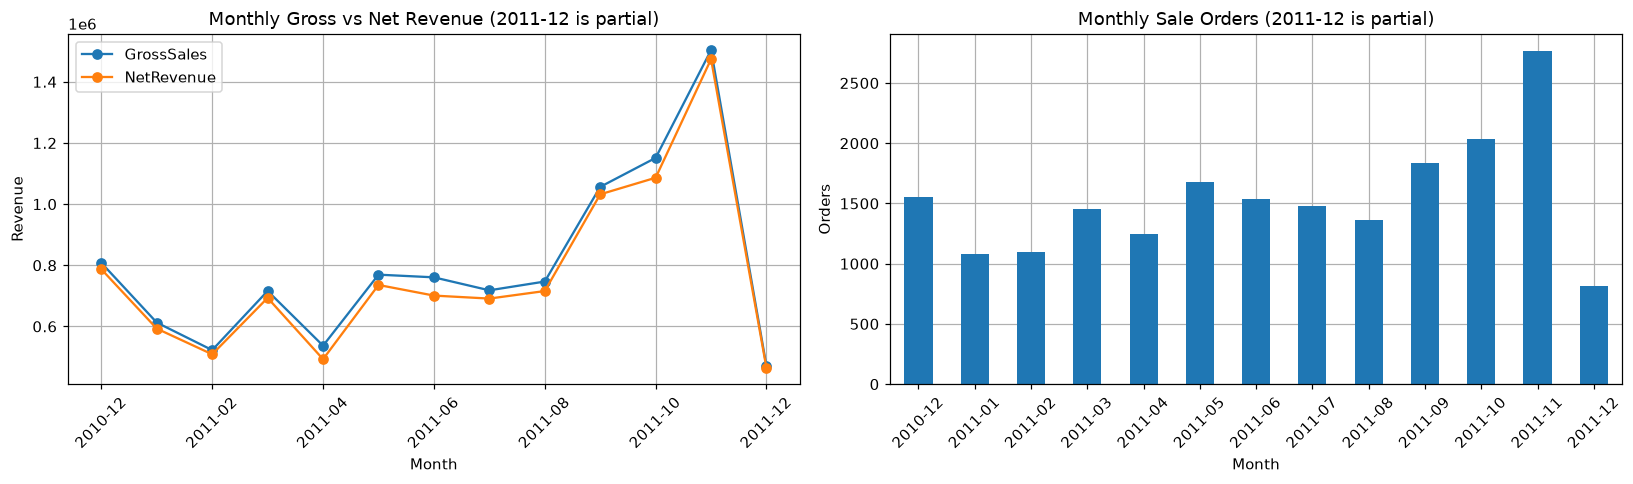

Insight 2: 2011-11 is the strongest complete month by net revenue.
Follow-up: Increase inventory and retention activity before the strongest seasonal period.
Insight 3: 2011-11 has the highest number of sale orders among complete months.
Follow-up: Compare staffing and fulfillment capacity with the order peak. Sep-Nov contribute 37.8% of net revenue in the 12 complete months (Dec-2010 to Nov-2011).


In [19]:
monthly = pd.DataFrame(index=sorted(eda["YearMonth"].unique()))
monthly["GrossSales"] = sales.groupby("YearMonth")["TotalLineRevenue"].sum()
monthly["ReturnValue"] = -returns.groupby("YearMonth")["TotalLineRevenue"].sum()
monthly["NetRevenue"] = eda.groupby("YearMonth")["TotalLineRevenue"].sum()
monthly["Orders"] = sales.groupby("YearMonth")["InvoiceNo"].nunique()
monthly = monthly.fillna(0)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))

monthly[["GrossSales", "NetRevenue"]].plot(marker="o", ax=ax[0])
ax[0].set_title("Monthly Gross vs Net Revenue (2011-12 is partial)")
ax[0].set_xlabel("Month")
ax[0].set_ylabel("Revenue")
ax[0].tick_params(axis="x", rotation=45)

monthly["Orders"].plot(kind="bar", ax=ax[1])
ax[1].set_title("Monthly Sale Orders (2011-12 is partial)")
ax[1].set_xlabel("Month")
ax[1].set_ylabel("Orders")
ax[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

# Dec-2010 to Nov-2011 are 12 complete months; 2011-12 ends on the 9th (partial).
complete_months = monthly.loc["2010-12":"2011-11"]
peak_revenue_month = complete_months["NetRevenue"].idxmax()
peak_order_month = complete_months["Orders"].idxmax()
q4_share = complete_months.loc["2011-09":"2011-11", "NetRevenue"].sum() / complete_months["NetRevenue"].sum()

note(2, f"{peak_revenue_month} is the strongest complete month by net revenue.", "Increase inventory and retention activity before the strongest seasonal period.")
note(3, f"{peak_order_month} has the highest number of sale orders among complete months.", f"Compare staffing and fulfillment capacity with the order peak. Sep-Nov contribute {q4_share:.1%} of net revenue in the 12 complete months (Dec-2010 to Nov-2011).")


## 16. Weekday & hourly shopping behavior


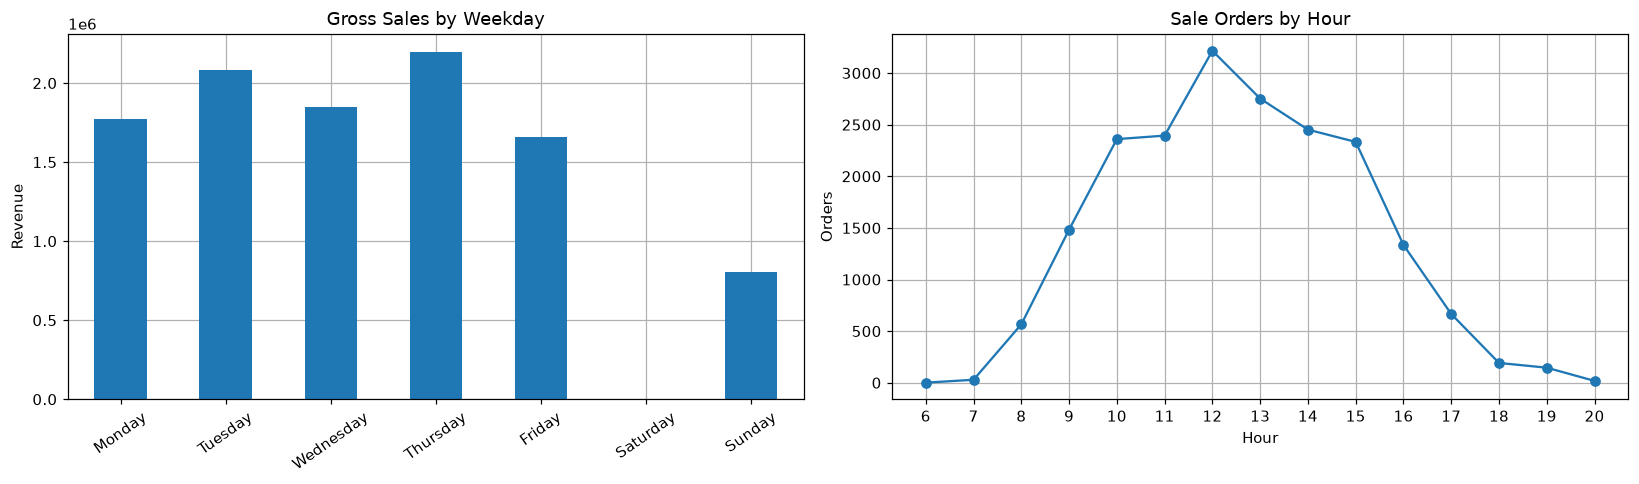

Insight 4: Thursday generates the highest gross sales by weekday.
Follow-up: Concentrate promotions and operational coverage around the strongest weekdays.
Insight 5: 12:00 is the busiest hour by number of sale orders.
Follow-up: Avoid maintenance during the busiest hours and align customer support coverage with demand.


In [20]:
day_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday = sales.groupby("DayOfWeek").agg(
    Revenue=("TotalLineRevenue", "sum"),
    Orders=("InvoiceNo", "nunique")
).reindex(day_order).fillna(0)
weekday["AOV"] = weekday["Revenue"] / weekday["Orders"].replace(0, np.nan)

hourly = sales.groupby("Hour").agg(
    Revenue=("TotalLineRevenue", "sum"),
    Orders=("InvoiceNo", "nunique")
)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
weekday["Revenue"].plot(kind="bar", ax=ax[0])
ax[0].set_title("Gross Sales by Weekday")
ax[0].set_xlabel("")
ax[0].set_ylabel("Revenue")
ax[0].tick_params(axis="x", rotation=35)

hourly["Orders"].plot(marker="o", ax=ax[1])
ax[1].set_title("Sale Orders by Hour")
ax[1].set_xlabel("Hour")
ax[1].set_ylabel("Orders")
ax[1].set_xticks(hourly.index)

plt.tight_layout()
plt.show()

top_day = weekday["Revenue"].idxmax()
top_hour = hourly["Orders"].idxmax()

note(4, f"{top_day} generates the highest gross sales by weekday.", "Concentrate promotions and operational coverage around the strongest weekdays.")
note(5, f"{top_hour}:00 is the busiest hour by number of sale orders.", "Avoid maintenance during the busiest hours and align customer support coverage with demand.")


## 17. Product performance — revenue, units & returns


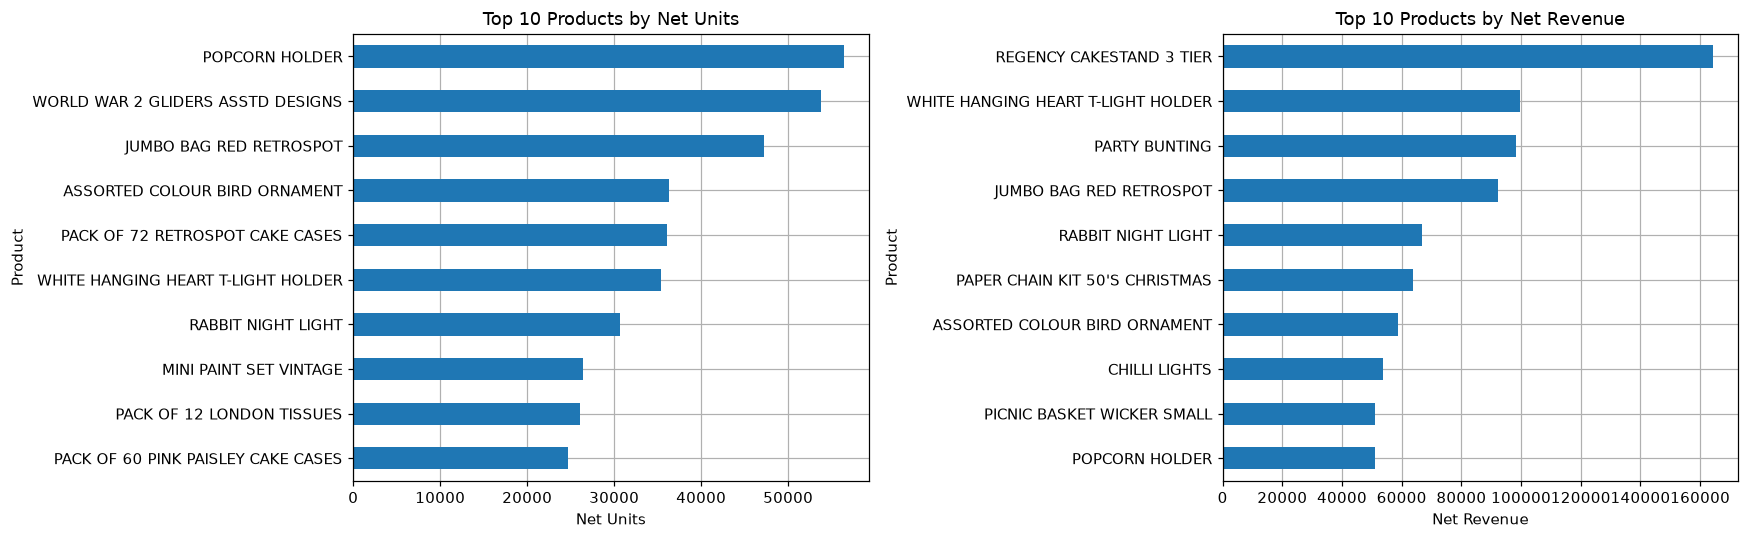

Insight 6: POPCORN HOLDER leads product demand by net units.
Follow-up: Protect availability of high-volume products and use them for basket-building offers.
Insight 7: REGENCY CAKESTAND 3 TIER leads merchandise net revenue.
Follow-up: Prioritize margin, stock availability, and cross-sell recommendations around high-value products.


In [21]:
product_summary = product_sales.groupby("StockCode").agg(
    Product=("ProductName", "first"),
    GrossUnits=("Quantity", "sum"),
    GrossRevenue=("TotalLineRevenue", "sum")
)

product_summary["ReturnUnits"] = -product_returns.groupby("StockCode")["Quantity"].sum()
product_summary["ReturnValue"] = -product_returns.groupby("StockCode")["TotalLineRevenue"].sum()
product_summary = product_summary.fillna(0)

product_summary["NetUnits"] = product_summary["GrossUnits"] - product_summary["ReturnUnits"]
product_summary["NetRevenue"] = product_summary["GrossRevenue"] - product_summary["ReturnValue"]
product_summary["ReturnRate"] = (
    product_summary["ReturnValue"] /
    product_summary["GrossRevenue"].replace(0, np.nan)
).fillna(0)

top_units = product_summary.nlargest(10, "NetUnits").sort_values("NetUnits")
top_revenue = product_summary.nlargest(10, "NetRevenue").sort_values("NetRevenue")

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
top_units.set_index("Product")["NetUnits"].plot(kind="barh", ax=ax[0])
ax[0].set_title("Top 10 Products by Net Units")
ax[0].set_xlabel("Net Units")

top_revenue.set_index("Product")["NetRevenue"].plot(kind="barh", ax=ax[1])
ax[1].set_title("Top 10 Products by Net Revenue")
ax[1].set_xlabel("Net Revenue")

plt.tight_layout()
plt.show()

best_units_product = product_summary.loc[product_summary["NetUnits"].idxmax(), "Product"]
best_revenue_product = product_summary.loc[product_summary["NetRevenue"].idxmax(), "Product"]

note(6, f"{best_units_product} leads product demand by net units.", "Protect availability of high-volume products and use them for basket-building offers.")
note(7, f"{best_revenue_product} leads merchandise net revenue.", "Prioritize margin, stock availability, and cross-sell recommendations around high-value products.")


## 18. Product revenue concentration — Pareto


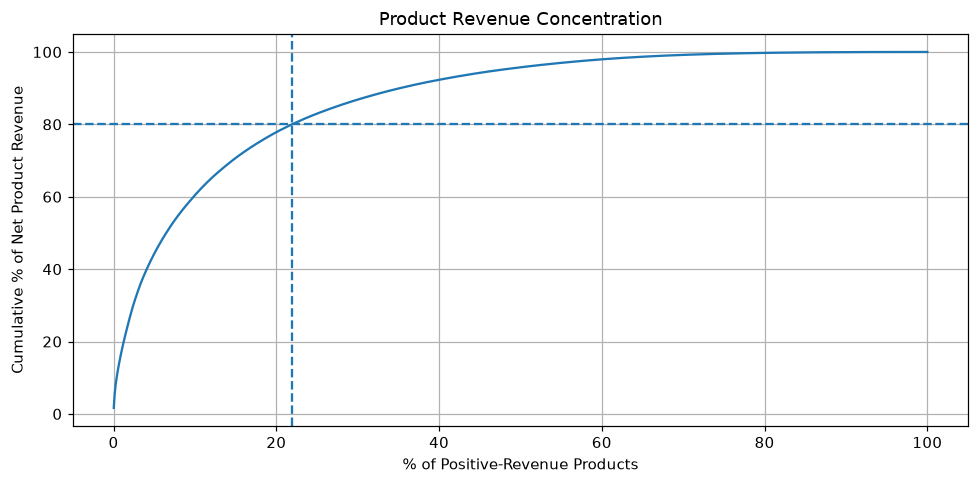

Insight 8: Only 21.9% of positive-revenue products generate 80% of product revenue.
Follow-up: Use ABC inventory priorities instead of managing every SKU with the same attention.
Insight 9: The top 10 products alone contribute 8.2% of positive product revenue.
Follow-up: Monitor top products separately for stockouts, returns, and sudden demand changes.


In [22]:
positive_product_revenue = (
    product_summary.loc[product_summary["NetRevenue"] > 0, "NetRevenue"]
    .sort_values(ascending=False)
)

cumulative_share = positive_product_revenue.cumsum() / positive_product_revenue.sum()
products_for_80 = (cumulative_share < 0.80).sum() + 1
product_share_for_80 = products_for_80 / len(positive_product_revenue)
top10_product_share = positive_product_revenue.head(10).sum() / positive_product_revenue.sum()

plt.figure(figsize=(9, 4.5))
plt.plot(
    np.arange(1, len(cumulative_share) + 1) / len(cumulative_share) * 100,
    cumulative_share * 100
)
plt.axhline(80, linestyle="--")
plt.axvline(product_share_for_80 * 100, linestyle="--")
plt.xlabel("% of Positive-Revenue Products")
plt.ylabel("Cumulative % of Net Product Revenue")
plt.title("Product Revenue Concentration")
plt.tight_layout()
plt.show()

note(8, f"Only {product_share_for_80:.1%} of positive-revenue products generate 80% of product revenue.", "Use ABC inventory priorities instead of managing every SKU with the same attention.")
note(9, f"The top 10 products alone contribute {top10_product_share:.1%} of positive product revenue.", "Monitor top products separately for stockouts, returns, and sudden demand changes.")


## 19. Inactive product candidates — final 90 days

This is **not inventory stock-on-hand data**. It only flags historically active products with no sales in the final 90 days so the business can investigate them.


In [23]:
last_sale_date = product_sales["InvoiceDate"].max()
cutoff_90 = last_sale_date - pd.Timedelta(days=90)

historical_units = (
    product_sales[product_sales["InvoiceDate"] < cutoff_90]
    .groupby("ProductName")["Quantity"]
    .sum()
)

recent_units = (
    product_sales[product_sales["InvoiceDate"] >= cutoff_90]
    .groupby("ProductName")["Quantity"]
    .sum()
)

product_activity = pd.DataFrame({
    "HistoricalUnits": historical_units,
    "Last90DaysUnits": recent_units
}).fillna(0)

high_history_limit = product_activity["HistoricalUnits"].quantile(0.75)

inactive_products = product_activity[
    (product_activity["HistoricalUnits"] >= high_history_limit) &
    (product_activity["Last90DaysUnits"] == 0)
].sort_values("HistoricalUnits", ascending=False)

print("High-history products with zero units in final 90 days:", len(inactive_products))
display(inactive_products.head(15))

note(10, f"{len(inactive_products)} historically strong products became inactive in the final 90 days.", "Investigate discontinuation, stock availability, seasonality, or catalogue changes before calling them dead stock.")


High-history products with zero units in final 90 days: 23


,HistoricalUnits,Last90DaysUnits
ProductName,,
ESSENTIAL BALM 3.5G TIN IN ENVELOPE,"5,884.00",0.00
FINE WICKER HEART,"2,642.00",0.00
TEA TIME TEA TOWELS,"2,600.00",0.00
ASSORTED LAQUERED INCENSE HOLDERS,"2,545.00",0.00
BLUE POLKADOT COFFEE MUG,"2,054.00",0.00
VINTAGE BILLBOARD TEA MUG,"1,949.00",0.00
JUMBO BAG CHARLIE AND LOLA TOYS,"1,932.00",0.00
PAPER BUNTING COLOURED LACE,"1,893.00",0.00
POLKADOT COFFEE CUP & SAUCER PINK,"1,570.00",0.00


Insight 10: 23 historically strong products became inactive in the final 90 days.
Follow-up: Investigate discontinuation, stock availability, seasonality, or catalogue changes before calling them dead stock.


## 20. Order value & basket behavior


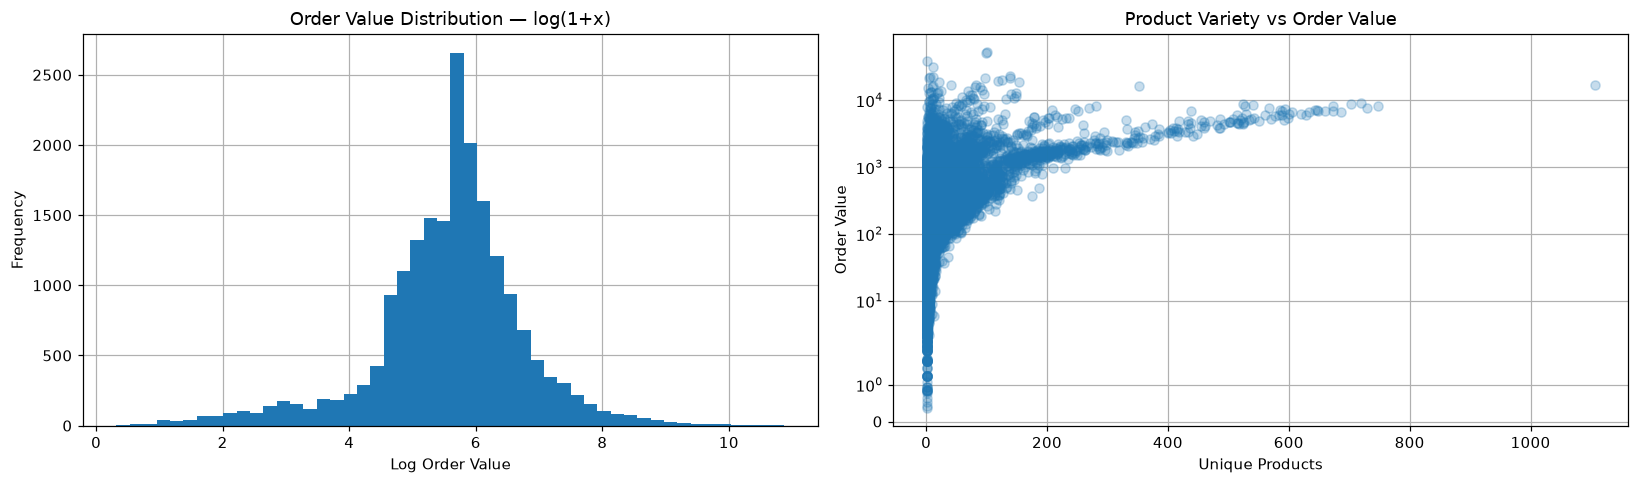

Insight 11: The typical sale order is £303.60 by median value.
Follow-up: Use median order value as a realistic baseline for upsell targets rather than the mean alone.
Insight 12: Median basket size is 152 units, while the top 10% start around 531 units.
Follow-up: Separate normal retail behavior from bulk/wholesale-like orders in customer profiling.


In [24]:
invoice_features = product_sales.groupby("InvoiceNo").agg(
    CustomerID=("CustomerID", "first"),
    InvoiceDate=("InvoiceDate", "min"),
    Country=("Country", "first"),
    UniqueProducts=("StockCode", "nunique"),
    BasketUnits=("Quantity", "sum"),
    ProductValue=("TotalLineRevenue", "sum")
)

# Full order value also includes customer-linked postage / discounts / service lines.
invoice_features["InvoiceValue"] = sales.groupby("InvoiceNo")["TotalLineRevenue"].sum()

bulk_limit = invoice_features["BasketUnits"].quantile(0.90)
invoice_features["IsBulkOrder"] = invoice_features["BasketUnits"] >= bulk_limit

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
np.log1p(invoice_features["InvoiceValue"].clip(lower=0)).plot(kind="hist", bins=50, ax=ax[0])
ax[0].set_title("Order Value Distribution — log(1+x)")
ax[0].set_xlabel("Log Order Value")

ax[1].scatter(
    invoice_features["UniqueProducts"],
    invoice_features["InvoiceValue"],
    alpha=0.25
)
ax[1].set_yscale("symlog")
ax[1].set_title("Product Variety vs Order Value")
ax[1].set_xlabel("Unique Products")
ax[1].set_ylabel("Order Value")

plt.tight_layout()
plt.show()

median_order = invoice_features["InvoiceValue"].median()
median_units = invoice_features["BasketUnits"].median()
p90_units = invoice_features["BasketUnits"].quantile(0.90)

note(11, f"The typical sale order is £{median_order:,.2f} by median value.", "Use median order value as a realistic baseline for upsell targets rather than the mean alone.")
note(12, f"Median basket size is {median_units:.0f} units, while the top 10% start around {p90_units:.0f} units.", "Separate normal retail behavior from bulk/wholesale-like orders in customer profiling.")


## 21. Customer value, frequency & recency


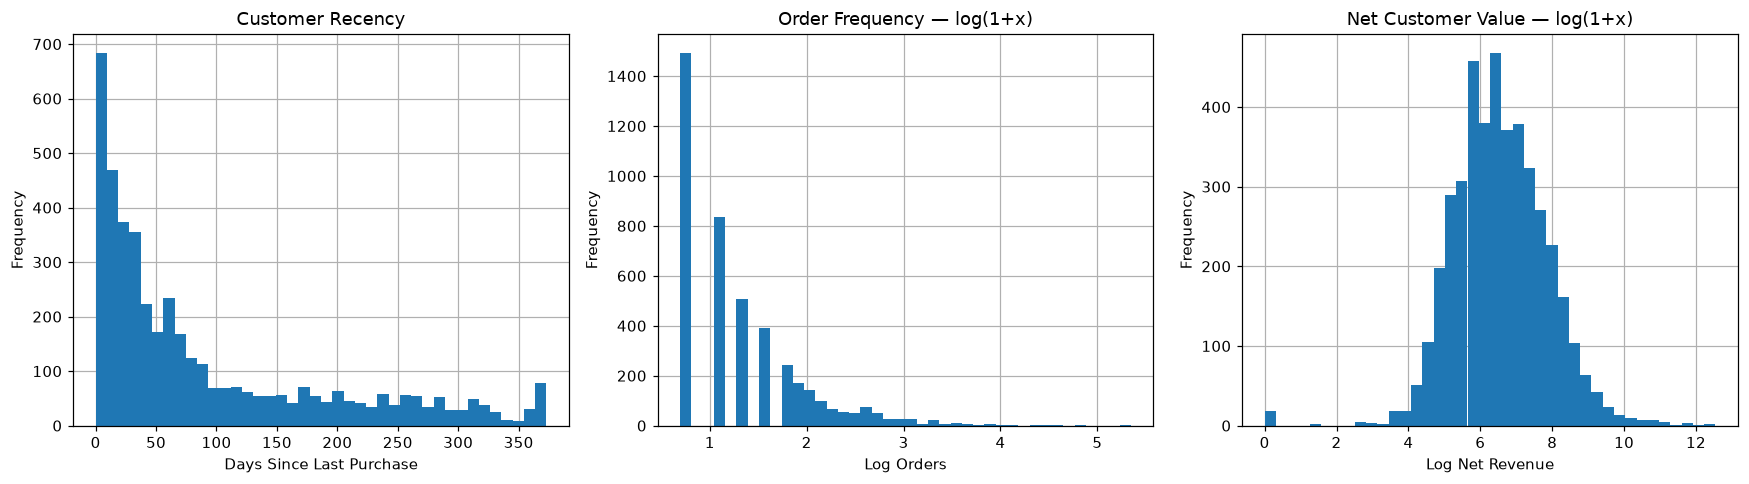

Insight 13: 34.4% of known customers purchased only once.
Follow-up: Build a second-purchase campaign for one-time buyers before focusing only on acquisition.
Insight 14: The top 20% of customers generate 73.7% of customer net value; the top 1% generate 30.0%.
Follow-up: Protect high-value customers with retention treatment while avoiding over-discounting them.


In [25]:
snapshot_date = sales["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)

customer_eda = customer_lines.groupby("CustomerID").agg(
    NetRevenue=("TotalLineRevenue", "sum")
)

customer_eda["Orders"] = customer_sales.groupby("CustomerID")["InvoiceNo"].nunique()
customer_eda["LastPurchase"] = customer_sales.groupby("CustomerID")["InvoiceDate"].max()
customer_eda["Recency"] = (snapshot_date - customer_eda["LastPurchase"]).dt.days
customer_eda["GrossSales"] = customer_sales.groupby("CustomerID")["TotalLineRevenue"].sum()
customer_eda["AOV"] = customer_eda["GrossSales"] / customer_eda["Orders"]
customer_eda = customer_eda.dropna(subset=["Orders"]).sort_values("NetRevenue", ascending=False)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
customer_eda["Recency"].plot(kind="hist", bins=40, ax=ax[0])
ax[0].set_title("Customer Recency")
ax[0].set_xlabel("Days Since Last Purchase")

np.log1p(customer_eda["Orders"]).plot(kind="hist", bins=40, ax=ax[1])
ax[1].set_title("Order Frequency — log(1+x)")
ax[1].set_xlabel("Log Orders")

np.log1p(customer_eda["NetRevenue"].clip(lower=0)).plot(kind="hist", bins=40, ax=ax[2])
ax[2].set_title("Net Customer Value — log(1+x)")
ax[2].set_xlabel("Log Net Revenue")

plt.tight_layout()
plt.show()

one_time_share = (customer_eda["Orders"] == 1).mean()
top_1_n = max(1, int(np.ceil(len(customer_eda) * 0.01)))
top_20_n = max(1, int(np.ceil(len(customer_eda) * 0.20)))
top_1_share = customer_eda.head(top_1_n)["NetRevenue"].sum() / customer_eda["NetRevenue"].sum()
top_20_share = customer_eda.head(top_20_n)["NetRevenue"].sum() / customer_eda["NetRevenue"].sum()

note(13, f"{one_time_share:.1%} of known customers purchased only once.", "Build a second-purchase campaign for one-time buyers before focusing only on acquisition.")
note(14, f"The top 20% of customers generate {top_20_share:.1%} of customer net value; the top 1% generate {top_1_share:.1%}.", "Protect high-value customers with retention treatment while avoiding over-discounting them.")


## 22. Top customers & customer concentration


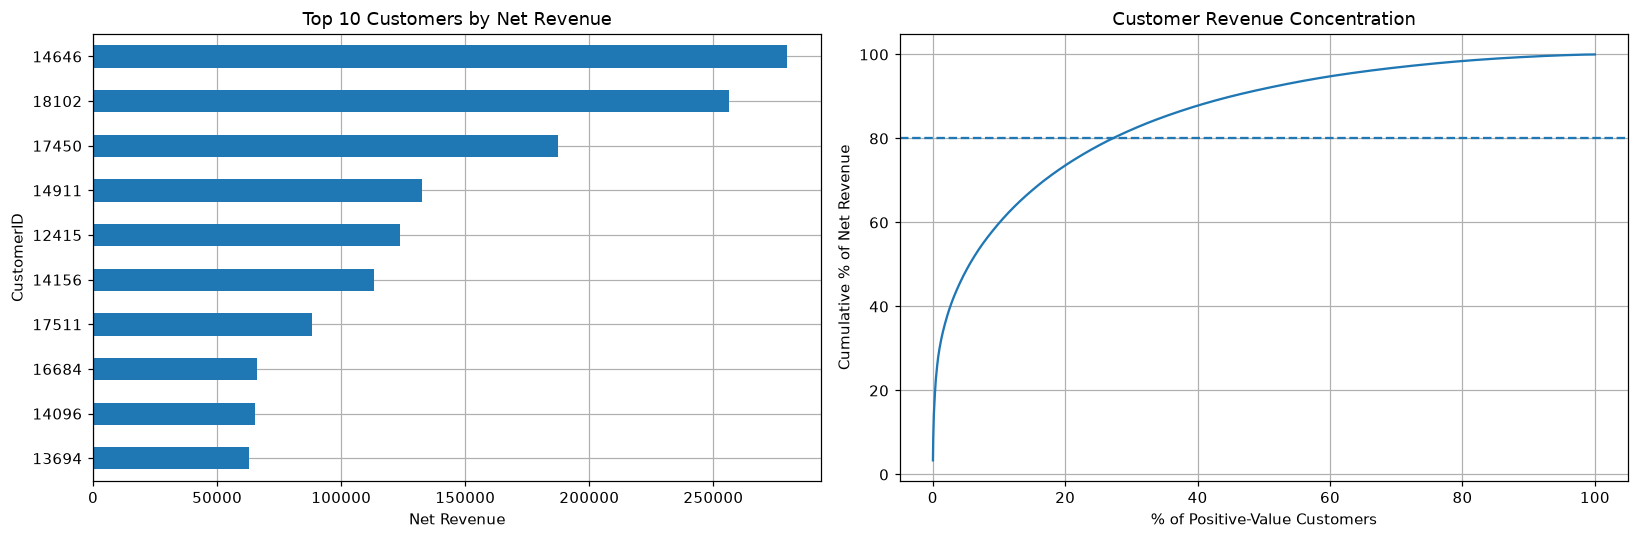

Insight 15: 27.1% of positive-value customers generate 80% of customer net revenue.
Follow-up: RFM segmentation should distinguish high-value repeat customers from the long low-value tail.


In [26]:
top_customers = customer_eda.head(10).sort_values("NetRevenue")

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
top_customers["NetRevenue"].plot(kind="barh", ax=ax[0])
ax[0].set_title("Top 10 Customers by Net Revenue")
ax[0].set_xlabel("Net Revenue")
ax[0].set_ylabel("CustomerID")

customer_positive = customer_eda[customer_eda["NetRevenue"] > 0]["NetRevenue"].sort_values(ascending=False)
customer_curve = customer_positive.cumsum() / customer_positive.sum()
ax[1].plot(
    np.arange(1, len(customer_curve) + 1) / len(customer_curve) * 100,
    customer_curve * 100
)
ax[1].axhline(80, linestyle="--")
ax[1].set_title("Customer Revenue Concentration")
ax[1].set_xlabel("% of Positive-Value Customers")
ax[1].set_ylabel("Cumulative % of Net Revenue")

plt.tight_layout()
plt.show()

customers_for_80 = (customer_curve < 0.80).sum() + 1
customer_share_for_80 = customers_for_80 / len(customer_curve)

note(15, f"{customer_share_for_80:.1%} of positive-value customers generate 80% of customer net revenue.", "RFM segmentation should distinguish high-value repeat customers from the long low-value tail.")


## 23. Geographic performance


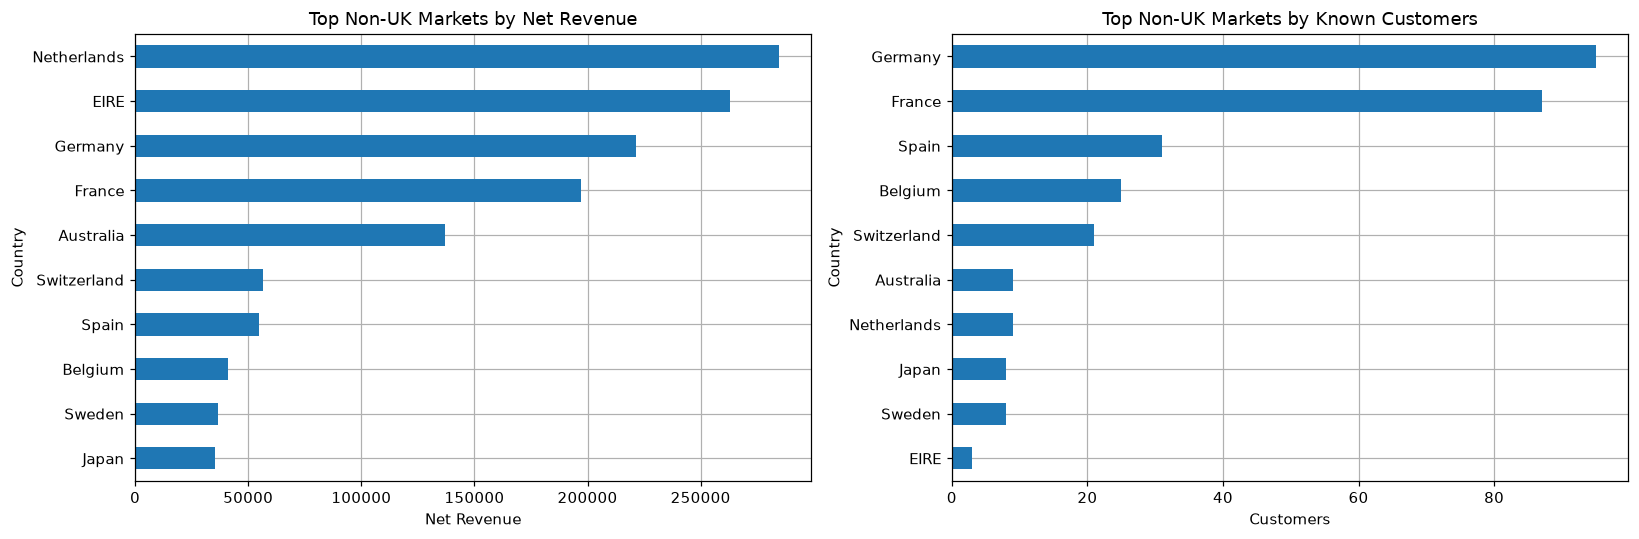

,NetRevenue,Customers,SaleOrders,GrossSales,AOV
Country,,,,,
United Kingdom,"8,414,815.91",3948,18003,"8,731,098.84",484.98
Netherlands,"284,661.54",9,94,"285,446.34","3,036.66"
EIRE,"262,993.38",3,288,"283,140.52",983.13
Germany,"221,509.47",95,457,"228,678.40",500.39
France,"197,317.11",87,392,"209,625.37",534.76
Australia,"137,009.77",9,57,"138,453.81","2,429.01"
Switzerland,"56,363.05",21,54,"57,067.60","1,056.81"
Spain,"54,756.03",31,90,"61,558.56",683.98
Belgium,"40,910.96",25,98,"41,196.34",420.37


Insight 16: The UK contributes 84.4% of total net revenue, showing strong home-market concentration.
Follow-up: Report UK and international performance separately so the UK does not hide smaller-market patterns.
Insight 17: Netherlands is the strongest non-UK market by net revenue.
Follow-up: Review repeat buying, AOV, and delivery economics before prioritizing international expansion.


In [27]:
country_summary = eda.groupby("Country").agg(
    NetRevenue=("TotalLineRevenue", "sum"),
    Customers=("CustomerID", "nunique")
)
country_summary["SaleOrders"] = sales.groupby("Country")["InvoiceNo"].nunique()
country_summary["GrossSales"] = sales.groupby("Country")["TotalLineRevenue"].sum()
country_summary["AOV"] = country_summary["GrossSales"] / country_summary["SaleOrders"]
country_summary = country_summary.fillna(0).sort_values("NetRevenue", ascending=False)

uk_share = country_summary.loc["United Kingdom", "NetRevenue"] / country_summary["NetRevenue"].sum()
non_uk = country_summary.drop(index="United Kingdom", errors="ignore").head(10)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
non_uk["NetRevenue"].sort_values().plot(kind="barh", ax=ax[0])
ax[0].set_title("Top Non-UK Markets by Net Revenue")
ax[0].set_xlabel("Net Revenue")

non_uk["Customers"].sort_values().plot(kind="barh", ax=ax[1])
ax[1].set_title("Top Non-UK Markets by Known Customers")
ax[1].set_xlabel("Customers")

plt.tight_layout()
plt.show()

display(country_summary.head(12))

best_non_uk = non_uk["NetRevenue"].idxmax()
note(16, f"The UK contributes {uk_share:.1%} of total net revenue, showing strong home-market concentration.", "Report UK and international performance separately so the UK does not hide smaller-market patterns.")
note(17, f"{best_non_uk} is the strongest non-UK market by net revenue.", "Review repeat buying, AOV, and delivery economics before prioritizing international expansion.")


## 24. Returns & cancellation behavior


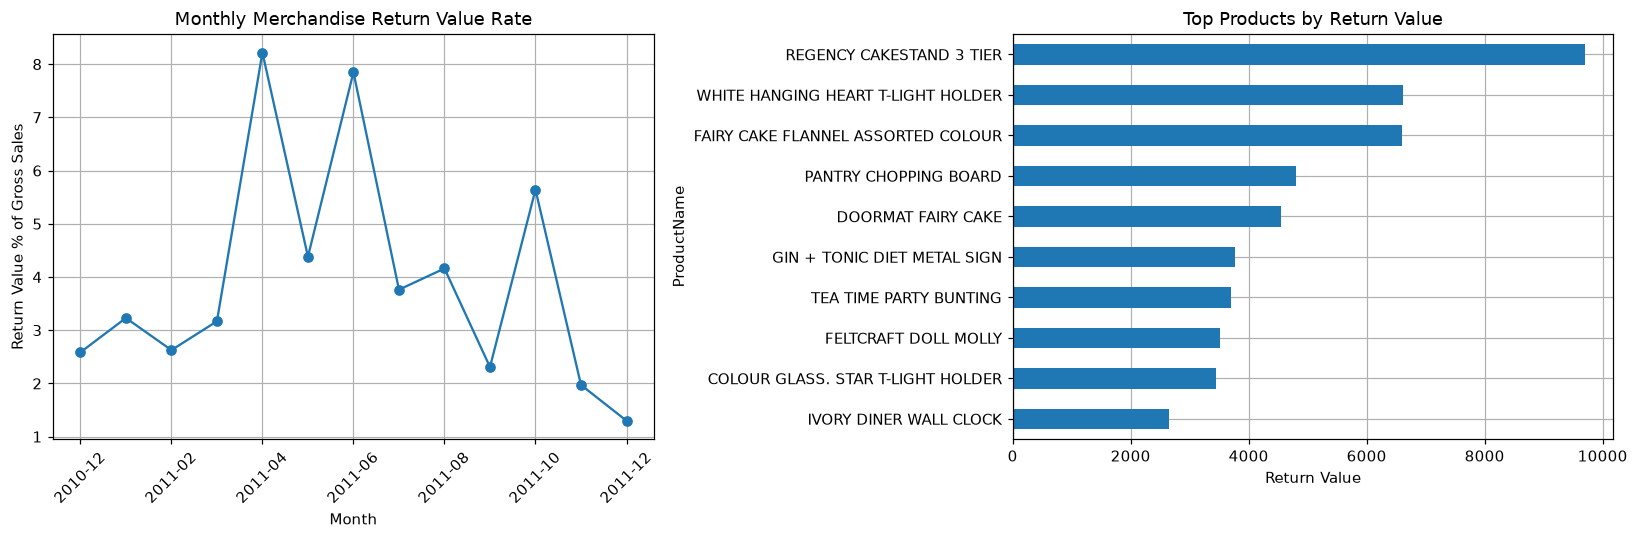

Insight 18: 2011-04 has the highest merchandise return-value rate among complete months.
Follow-up: Investigate whether that month had product-quality, fulfillment, or seasonal-return issues.
Insight 19: REGENCY CAKESTAND 3 TIER has the highest merchandise return value.
Follow-up: Review this product separately for quality, description accuracy, and customer expectations.


In [28]:
monthly_returns = pd.DataFrame(index=monthly.index)
monthly_returns["GrossSales"] = monthly["GrossSales"]
monthly_returns["ReturnValue"] = monthly["ReturnValue"]
monthly_returns["ReturnRate"] = (
    monthly_returns["ReturnValue"] /
    monthly_returns["GrossSales"].replace(0, np.nan)
).fillna(0)

return_product_value = (
    -product_returns.groupby("ProductName")["TotalLineRevenue"].sum()
).sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
(monthly_returns["ReturnRate"] * 100).plot(marker="o", ax=ax[0])
ax[0].set_title("Monthly Merchandise Return Value Rate")
ax[0].set_xlabel("Month")
ax[0].set_ylabel("Return Value % of Gross Sales")
ax[0].tick_params(axis="x", rotation=45)

return_product_value.head(10).sort_values().plot(kind="barh", ax=ax[1])
ax[1].set_title("Top Products by Return Value")
ax[1].set_xlabel("Return Value")

plt.tight_layout()
plt.show()

highest_return_month = monthly_returns.loc[:"2011-11", "ReturnRate"].idxmax()
highest_return_product = return_product_value.index[0]

note(18, f"{highest_return_month} has the highest merchandise return-value rate among complete months.", "Investigate whether that month had product-quality, fulfillment, or seasonal-return issues.")
note(19, f"{highest_return_product} has the highest merchandise return value.", "Review this product separately for quality, description accuracy, and customer expectations.")


## 25. Guest checkout / missing-customer impact


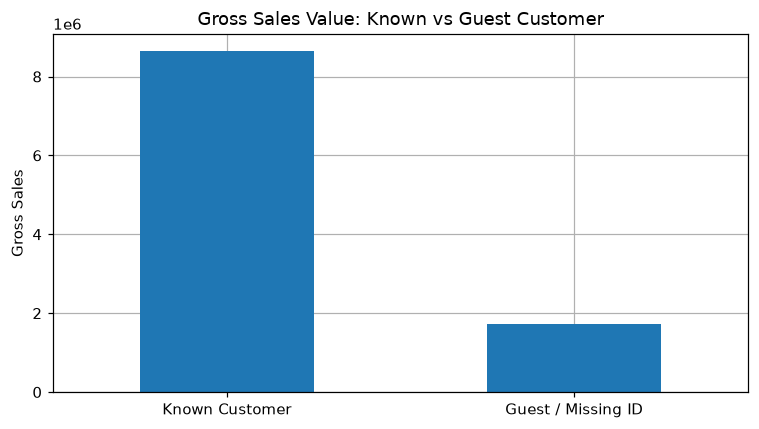

Insight 20: Guest/missing-ID invoices represent 7.1% of sale invoices and 16.7% of gross sales value.
Follow-up: Improve customer identification if the business wants stronger retention and RFM coverage; never invent missing CustomerIDs.


In [29]:
guest_sales = sales[~sales["HasCustomer"]].copy()
known_sales = sales[sales["HasCustomer"]].copy()

guest_invoice_share = guest_sales["InvoiceNo"].nunique() / sales["InvoiceNo"].nunique()
guest_value_share = guest_sales["TotalLineRevenue"].sum() / sales["TotalLineRevenue"].sum()

customer_status_value = pd.Series({
    "Known Customer": known_sales["TotalLineRevenue"].sum(),
    "Guest / Missing ID": guest_sales["TotalLineRevenue"].sum()
})

plt.figure(figsize=(7, 4))
customer_status_value.plot(kind="bar")
plt.title("Gross Sales Value: Known vs Guest Customer")
plt.ylabel("Gross Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

note(20, f"Guest/missing-ID invoices represent {guest_invoice_share:.1%} of sale invoices and {guest_value_share:.1%} of gross sales value.", "Improve customer identification if the business wants stronger retention and RFM coverage; never invent missing CustomerIDs.")


## 26. Bulk / wholesale behavior & service lines


In [30]:
known_invoice_features = invoice_features.dropna(subset=["CustomerID"]).copy()

bulk_orders = known_invoice_features[known_invoice_features["IsBulkOrder"]]
normal_orders = known_invoice_features[~known_invoice_features["IsBulkOrder"]]

bulk_order_share = len(bulk_orders) / len(known_invoice_features)
bulk_value_share = bulk_orders["InvoiceValue"].sum() / known_invoice_features["InvoiceValue"].sum()

bulk_compare = pd.DataFrame({
    "Order Type": ["Normal", "Bulk"],
    "Orders": [len(normal_orders), len(bulk_orders)],
    "Average Order Value": [normal_orders["InvoiceValue"].mean(), bulk_orders["InvoiceValue"].mean()],
    "Average Basket Units": [normal_orders["BasketUnits"].mean(), bulk_orders["BasketUnits"].mean()]
})

display(bulk_compare)
print(f"Bulk threshold: {bulk_limit:.0f} units")
print(f"Bulk orders: {bulk_order_share:.1%} of known-customer orders, {bulk_value_share:.1%} of known-order value")

service_summary = eda[eda["IsService"]].groupby("StockCode").agg(
    Rows=("InvoiceNo", "size"),
    NetValue=("TotalLineRevenue", "sum")
).sort_values("Rows", ascending=False)

display(service_summary)

print("Business follow-up: Keep bulk behavior and service lines visible in profiling, but do not treat service codes as merchandise demand.")


,Order Type,Orders,Average Order Value,Average Basket Units
0,Normal,16660,312.37,167.21
1,Bulk,1740,"1,938.21","1,264.84"


Bulk threshold: 531 units
Bulk orders: 9.5% of known-customer orders, 39.3% of known-order value


,Rows,NetValue
StockCode,,
POST,1252,"66,230.64"
DOT,707,"206,245.48"
M,561,"-69,031.64"
C2,143,"6,986.00"
D,77,"-5,696.22"
S,62,"-3,039.65"
GIFT_0001_20,9,167.05
GIFT_0001_10,8,74.97
GIFT_0001_30,7,175.53


Business follow-up: Keep bulk behavior and service lines visible in profiling, but do not treat service codes as merchandise demand.


The EDA now connects every major chart to a business decision: revenue seasonality, timing, products, concentration, inactivity, baskets, customer value, geography, returns, guest activity, and bulk behavior. These findings provide the business context needed before RFM segmentation.


# 27. Business insights summary

In [31]:
pd.set_option("display.max_colwidth", None)
insight_table = pd.DataFrame(insights).sort_values("#").set_index("#")
print("Total insights:", len(insight_table))
display(insight_table)

Total insights: 20


,Insight,Follow-up
#,,
1,"The business generated £9,973,695 net revenue after returns.","Track net revenue, not gross sales alone, because returns remove 2.30% of merchandise gross sales."
2,2011-11 is the strongest complete month by net revenue.,Increase inventory and retention activity before the strongest seasonal period.
3,2011-11 has the highest number of sale orders among complete months.,Compare staffing and fulfillment capacity with the order peak. Sep-Nov contribute 37.8% of net revenue in the 12 complete months (Dec-2010 to Nov-2011).
4,Thursday generates the highest gross sales by weekday.,Concentrate promotions and operational coverage around the strongest weekdays.
5,12:00 is the busiest hour by number of sale orders.,Avoid maintenance during the busiest hours and align customer support coverage with demand.
6,POPCORN HOLDER leads product demand by net units.,Protect availability of high-volume products and use them for basket-building offers.
7,REGENCY CAKESTAND 3 TIER leads merchandise net revenue.,"Prioritize margin, stock availability, and cross-sell recommendations around high-value products."
8,Only 21.9% of positive-revenue products generate 80% of product revenue.,Use ABC inventory priorities instead of managing every SKU with the same attention.
9,The top 10 products alone contribute 8.2% of positive product revenue.,"Monitor top products separately for stockouts, returns, and sudden demand changes."


# 28. Customer-level feature engineering for RFM & segment profiling


In [32]:
# Customer sale summary.
customer_features = customer_sales.groupby("CustomerID").agg(
    FirstPurchase=("InvoiceDate", "min"),
    LastPurchase=("InvoiceDate", "max"),
    Frequency=("InvoiceNo", "nunique"),
    GrossSales=("TotalLineRevenue", "sum")
)

# Net value includes returns and customer-linked service/discount lines.
customer_features["Monetary"] = customer_lines.groupby("CustomerID")["TotalLineRevenue"].sum()

# Return behavior.
customer_return_value = (
    -returns.dropna(subset=["CustomerID"])
    .groupby("CustomerID")["TotalLineRevenue"]
    .sum()
)

customer_features["ReturnValue"] = customer_return_value.reindex(customer_features.index, fill_value=0)
customer_features["ReturnRate"] = (
    customer_features["ReturnValue"] /
    customer_features["GrossSales"]
).replace([np.inf, -np.inf], np.nan).fillna(0)

# Core RFM Recency.
customer_features["Recency"] = (
    snapshot_date - customer_features["LastPurchase"]
).dt.days

# Customer engagement over time.
customer_features["ActiveMonths"] = customer_sales.groupby("CustomerID")["YearMonth"].nunique()
customer_features["PurchaseSpanDays"] = (
    customer_features["LastPurchase"] - customer_features["FirstPurchase"]
).dt.days

customer_features["AvgDaysBetweenOrders"] = np.where(
    customer_features["Frequency"] > 1,
    customer_features["PurchaseSpanDays"] / (customer_features["Frequency"] - 1),
    np.nan
)

In [33]:
# Invoice behavior.
customer_invoice = known_invoice_features.groupby("CustomerID").agg(
    AvgOrderValue=("InvoiceValue", "mean"),
    AvgBasketUnits=("BasketUnits", "mean"),
    AvgUniqueProducts=("UniqueProducts", "mean"),
    BulkOrderRate=("IsBulkOrder", "mean")
)

customer_features = customer_features.join(customer_invoice)

# Product variety.
product_variety = (
    product_sales.dropna(subset=["CustomerID"])
    .groupby("CustomerID")["StockCode"]
    .nunique()
)
customer_features["ProductVariety"] = product_variety

# Geography.
customer_features["CountryCount"] = customer_sales.groupby("CustomerID")["Country"].nunique()
customer_features["MainCountry"] = customer_sales.groupby("CustomerID")["Country"].agg(
    lambda x: x.value_counts().index[0]
)
customer_features["IsUKCustomer"] = (customer_features["MainCountry"] == "United Kingdom").astype(int)

# Simple business flags.
customer_features["OneTimeBuyer"] = (customer_features["Frequency"] == 1).astype(int)
customer_features["MonetaryNonPositive"] = (customer_features["Monetary"] <= 0).astype(int)

customer_features = customer_features.reset_index()

display(customer_features.head())

,CustomerID,FirstPurchase,LastPurchase,Frequency,GrossSales,Monetary,ReturnValue,ReturnRate,Recency,ActiveMonths,PurchaseSpanDays,AvgDaysBetweenOrders,AvgOrderValue,AvgBasketUnits,AvgUniqueProducts,BulkOrderRate,ProductVariety,CountryCount,MainCountry,IsUKCustomer,OneTimeBuyer,MonetaryNonPositive
0,12347,2010-12-07 14:57:00,2011-12-07 15:52:00,7,"4,310.00","4,310.00",0.00,0.00,2,7,365,60.83,615.71,351.14,26.00,0.14,103.00,1,Iceland,0,0,0
1,12348,2010-12-16 19:09:00,2011-09-25 13:13:00,4,"1,797.24","1,797.24",0.00,0.00,75,4,282,94.00,449.31,583.00,5.75,0.50,21.00,1,Finland,0,0,0
2,12349,2011-11-21 09:51:00,2011-11-21 09:51:00,1,"1,757.55","1,757.55",0.00,0.00,18,1,0,NaN,"1,757.55",630.00,72.00,1.00,72.00,1,Italy,0,1,0
3,12350,2011-02-02 16:01:00,2011-02-02 16:01:00,1,334.40,334.40,0.00,0.00,310,1,0,NaN,334.40,196.00,16.00,0.00,16.00,1,Norway,0,1,0
4,12352,2011-02-16 12:33:00,2011-11-03 14:37:00,8,"2,506.04","1,545.41",960.63,0.38,36,4,260,37.14,237.96,75.14,11.00,0.00,57.00,1,Norway,0,0,0


## 29. Why these customer features help business decisions


In [34]:
feature_dictionary = pd.DataFrame({
    "Feature": [
        "Recency", "Frequency", "Monetary", "GrossSales", "ReturnValue", "ReturnRate",
        "AvgOrderValue", "AvgBasketUnits", "AvgUniqueProducts", "ProductVariety",
        "ActiveMonths", "PurchaseSpanDays", "AvgDaysBetweenOrders", "BulkOrderRate",
        "MainCountry", "IsUKCustomer", "OneTimeBuyer"
    ],
    "Business Use": [
        "Find active vs dormant customers",
        "Measure repeat purchasing",
        "Measure net customer value after returns",
        "Separate purchasing power from return impact",
        "Identify high-return customers",
        "Compare return behavior fairly across customer size",
        "Understand typical order value",
        "Detect large-basket / wholesale behavior",
        "Measure basket breadth",
        "Measure catalog engagement",
        "Measure consistency across months",
        "Measure relationship length",
        "Estimate purchase cadence",
        "Flag wholesale-like purchasing",
        "Support geographic targeting",
        "Separate UK vs international behavior",
        "Identify customers needing a second-purchase journey"
    ]
})

display(feature_dictionary)

,Feature,Business Use
0,Recency,Find active vs dormant customers
1,Frequency,Measure repeat purchasing
2,Monetary,Measure net customer value after returns
3,GrossSales,Separate purchasing power from return impact
4,ReturnValue,Identify high-return customers
5,ReturnRate,Compare return behavior fairly across customer size
6,AvgOrderValue,Understand typical order value
7,AvgBasketUnits,Detect large-basket / wholesale behavior
8,AvgUniqueProducts,Measure basket breadth
9,ProductVariety,Measure catalog engagement


# 30. Build the final RFM-ready dataset


In [35]:
rfm = customer_features[[
    "CustomerID", "Recency", "Frequency", "Monetary"
]].copy()

print("All customers with sale history:", len(rfm))
print("Customers with Monetary <= 0:", (rfm["Monetary"] <= 0).sum())

# Keep non-positive customers in customer_features for business investigation,
# but exclude them from the model-ready RFM table because log transformation
# and value-based segmentation require positive Monetary values.
rfm_ready = rfm[rfm["Monetary"] > 0].copy().reset_index(drop=True)

print("RFM-ready customers:", len(rfm_ready))

# Who is excluded? Returns and discounts cancelled out (or exceeded) their purchases.
display(
    rfm[rfm["Monetary"] <= 0]
    .merge(customer_features[["CustomerID", "GrossSales", "ReturnValue"]], on="CustomerID")
    .sort_values("Monetary")
)
display(rfm_ready.head())

All customers with sale history: 4336
Customers with Monetary <= 0: 14
RFM-ready customers: 4322


,CustomerID,Recency,Frequency,Monetary,GrossSales,ReturnValue
11,17603,78,1,"-1,165.30",394.72,"1,560.02"
5,15802,142,1,-451.42,451.42,902.84
10,17548,233,1,-141.48,103.30,244.78
7,16546,290,2,-95.93,787.15,883.08
1,13672,301,2,-71.46,186.39,257.85
2,14437,365,1,-43.40,63.00,106.40
6,16454,44,2,-8.15,6.90,15.05
12,18072,185,1,-0.00,247.44,247.44
4,14792,63,1,0.00,6.20,6.20
3,14557,85,1,0.00,788.38,788.38


,CustomerID,Recency,Frequency,Monetary
0,12347,2,7,"4,310.00"
1,12348,75,4,"1,797.24"
2,12349,18,1,"1,757.55"
3,12350,310,1,334.40
4,12352,36,8,"1,545.41"


In [36]:
# Final validation before clustering.
assert rfm_ready["CustomerID"].notna().all()
assert (rfm_ready["Recency"] >= 0).all()
assert (rfm_ready["Frequency"] > 0).all()
assert (rfm_ready["Monetary"] > 0).all()
assert rfm_ready["CustomerID"].is_unique

# 31. RFM scoring

Each customer receives a score from **1 to 5**:

- **Recency:** lower days = better score.
- **Frequency:** more purchase invoices = better score.
- **Monetary:** higher net customer value = better score.

`pd.qcut` is used to create five customer groups. Frequency contains many ties, so ties are broken by Monetary (not by row order) so the five quantile groups are possible and reproducible.


In [37]:
rfm_scored = rfm_ready.copy()

rfm_scored["R_Score"] = pd.qcut(
    rfm_scored["Recency"],
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

# Many customers share the same Frequency (34% have 1 invoice), so qcut needs a tie-break.
# Ties are broken by Monetary (higher spend ranks higher) so the score never depends on CustomerID order.
order = rfm_scored.sort_values(["Frequency", "Monetary"]).index
frequency_rank = pd.Series(np.arange(len(order)), index=order).reindex(rfm_scored.index)

rfm_scored["F_Score"] = pd.qcut(
    frequency_rank,
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm_scored["M_Score"] = pd.qcut(
    rfm_scored["Monetary"],
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm_scored["RFM_Score"] = (
    rfm_scored["R_Score"].astype(str) +
    rfm_scored["F_Score"].astype(str) +
    rfm_scored["M_Score"].astype(str)
)

rfm_scored["RFM_Total"] = (
    rfm_scored["R_Score"] +
    rfm_scored["F_Score"] +
    rfm_scored["M_Score"]
)

display(rfm_scored.head())

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,RFM_Total
0,12347,2,7,"4,310.00",5,5,5,555,15
1,12348,75,4,"1,797.24",2,4,4,244,10
2,12349,18,1,"1,757.55",4,2,4,424,10
3,12350,310,1,334.40,1,2,2,122,5
4,12352,36,8,"1,545.41",3,5,4,354,12


In [38]:
print("R score distribution")
display(rfm_scored["R_Score"].value_counts().sort_index())

print("F score distribution")
display(rfm_scored["F_Score"].value_counts().sort_index())

print("M score distribution")
display(rfm_scored["M_Score"].value_counts().sort_index())

R score distribution


R_Score
1    864
2    852
3    859
4    882
5    865
Name: count, dtype: int64

F score distribution


F_Score
1    865
2    864
3    864
4    864
5    865
Name: count, dtype: int64

M score distribution


M_Score
1    865
2    864
3    864
4    864
5    865
Name: count, dtype: int64

# 32. Rule-based RFM business segments

The scores are translated into business-friendly customer groups.

The rules use all three RFM dimensions and are intentionally simple so the segmentation can be explained to a business team.


In [39]:
conditions = [
    (rfm_scored["R_Score"] >= 4) & (rfm_scored["F_Score"] >= 4) & (rfm_scored["M_Score"] >= 4),

    (rfm_scored["R_Score"] >= 3) & (rfm_scored["F_Score"] >= 4) & (rfm_scored["M_Score"] >= 3),

    (rfm_scored["R_Score"] == 5) & (rfm_scored["F_Score"] <= 2),

    (rfm_scored["R_Score"] >= 4) & (rfm_scored["F_Score"].between(2, 3)),

    (rfm_scored["R_Score"] <= 2) & (rfm_scored["F_Score"] >= 3) & (rfm_scored["M_Score"] >= 3),

    (rfm_scored["R_Score"] <= 2) & (rfm_scored["F_Score"] <= 2),

    (rfm_scored["M_Score"] >= 4) & (rfm_scored["F_Score"] <= 3)
]

segments = [
    "Champions",
    "Loyal Customers",
    "New Customers",
    "Potential Loyalists",
    "At Risk",
    "Lost",
    "High Value"
]

rfm_scored["Segment"] = np.select(
    conditions,
    segments,
    default="Need Attention"
)

display(rfm_scored["Segment"].value_counts())

Segment
Lost                   1073
Champions              1004
Need Attention          722
At Risk                 526
Loyal Customers         422
Potential Loyalists     415
New Customers           102
High Value               58
Name: count, dtype: int64

# 33. Segment profile

A useful segment must answer three questions:

1. **How many customers are in it?**
2. **How valuable and active are they?**
3. **What should the business do next?**


In [40]:
segment_summary = rfm_scored.groupby("Segment").agg(
    Customers=("CustomerID", "nunique"),
    AvgRecency=("Recency", "mean"),
    AvgFrequency=("Frequency", "mean"),
    AvgMonetary=("Monetary", "mean"),
    TotalMonetary=("Monetary", "sum"),
    AvgRScore=("R_Score", "mean"),
    AvgFScore=("F_Score", "mean"),
    AvgMScore=("M_Score", "mean")
).sort_values("TotalMonetary", ascending=False)

segment_summary["CustomerShare_%"] = (
    segment_summary["Customers"] /
    segment_summary["Customers"].sum() * 100
)

segment_summary["RevenueShare_%"] = (
    segment_summary["TotalMonetary"] /
    segment_summary["TotalMonetary"].sum() * 100
)

segment_summary = segment_summary.round(2)

display(segment_summary)

,Customers,AvgRecency,AvgFrequency,AvgMonetary,TotalMonetary,AvgRScore,AvgFScore,AvgMScore,CustomerShare_%,RevenueShare_%
Segment,,,,,,,,,,
Champions,1004,12.45,10.70,"5,658.42","5,681,051.38",4.57,4.67,4.61,23.23,68.45
Loyal Customers,422,40.52,5.47,"2,030.85","857,020.73",3.37,4.32,3.95,9.76,10.33
At Risk,526,142.34,3.56,"1,446.12","760,657.99",1.75,3.62,3.71,12.17,9.17
Lost,1073,218.20,1.11,339.03,"363,775.46",1.36,1.47,1.73,24.83,4.38
Potential Loyalists,415,17.50,2.11,631.74,"262,172.32",4.31,2.74,2.67,9.60,3.16
Need Attention,722,65.57,1.76,352.37,"254,409.70",2.95,2.10,1.85,16.71,3.07
High Value,58,53.48,1.67,"1,539.39","89,284.90",3.00,2.67,4.17,1.34,1.08
New Customers,102,6.67,1.34,305.45,"31,155.61",5.00,1.60,1.65,2.36,0.38


In [41]:
business_actions = {
    "Champions": "Reward loyalty, early access, referrals, and premium offers.",
    "Loyal Customers": "Cross-sell related products and protect repeat purchasing.",
    "New Customers": "Use onboarding and second-purchase campaigns.",
    "Potential Loyalists": "Encourage the next purchase with relevant recommendations.",
    "At Risk": "Run win-back campaigns and investigate why activity stopped.",
    "Lost": "Use low-cost reactivation only when the expected value justifies it.",
    "High Value": "Protect large spenders and understand why purchase frequency is lower.",
    "Need Attention": "Use targeted offers based on recent behavior and product interests."
}

segment_actions = segment_summary[[
    "Customers", "CustomerShare_%",
    "AvgRecency", "AvgFrequency",
    "AvgMonetary", "RevenueShare_%"
]].copy()

segment_actions["BusinessAction"] = segment_actions.index.map(business_actions)

display(segment_actions)

,Customers,CustomerShare_%,AvgRecency,AvgFrequency,AvgMonetary,RevenueShare_%,BusinessAction
Segment,,,,,,,
Champions,1004,23.23,12.45,10.70,"5,658.42",68.45,"Reward loyalty, early access, referrals, and premium offers."
Loyal Customers,422,9.76,40.52,5.47,"2,030.85",10.33,Cross-sell related products and protect repeat purchasing.
At Risk,526,12.17,142.34,3.56,"1,446.12",9.17,Run win-back campaigns and investigate why activity stopped.
Lost,1073,24.83,218.20,1.11,339.03,4.38,Use low-cost reactivation only when the expected value justifies it.
Potential Loyalists,415,9.60,17.50,2.11,631.74,3.16,Encourage the next purchase with relevant recommendations.
Need Attention,722,16.71,65.57,1.76,352.37,3.07,Use targeted offers based on recent behavior and product interests.
High Value,58,1.34,53.48,1.67,"1,539.39",1.08,Protect large spenders and understand why purchase frequency is lower.
New Customers,102,2.36,6.67,1.34,305.45,0.38,Use onboarding and second-purchase campaigns.


# 34. RFM visualizations


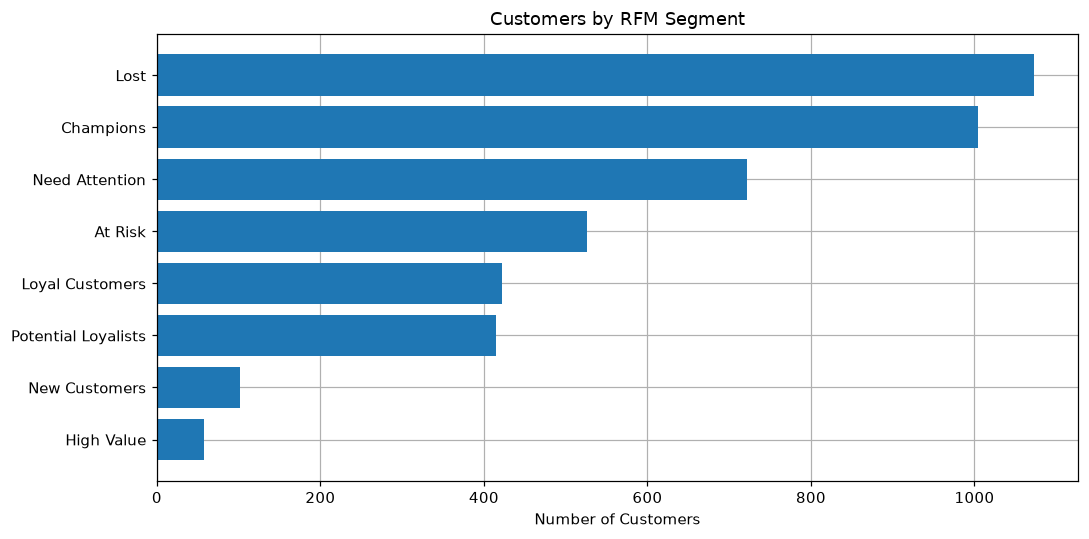

In [42]:
segment_counts = (
    rfm_scored["Segment"]
    .value_counts()
    .sort_values()
)

plt.figure(figsize=(10, 5))
plt.barh(segment_counts.index, segment_counts.values)
plt.title("Customers by RFM Segment")
plt.xlabel("Number of Customers")
plt.ylabel("")
plt.tight_layout()
plt.show()

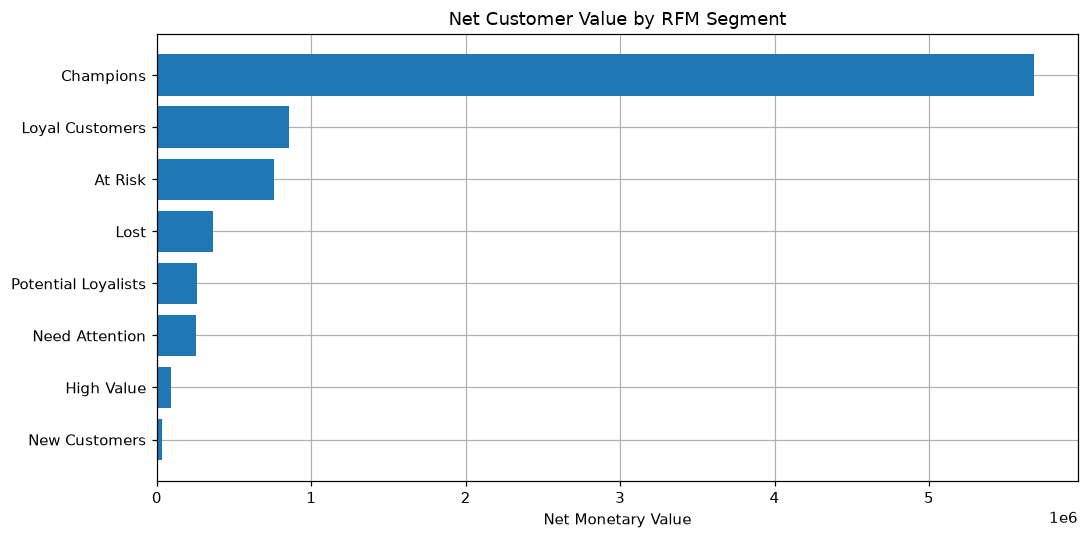

In [43]:
segment_revenue = (
    rfm_scored.groupby("Segment")["Monetary"]
    .sum()
    .sort_values()
)

plt.figure(figsize=(10, 5))
plt.barh(segment_revenue.index, segment_revenue.values)
plt.title("Net Customer Value by RFM Segment")
plt.xlabel("Net Monetary Value")
plt.ylabel("")
plt.tight_layout()
plt.show()

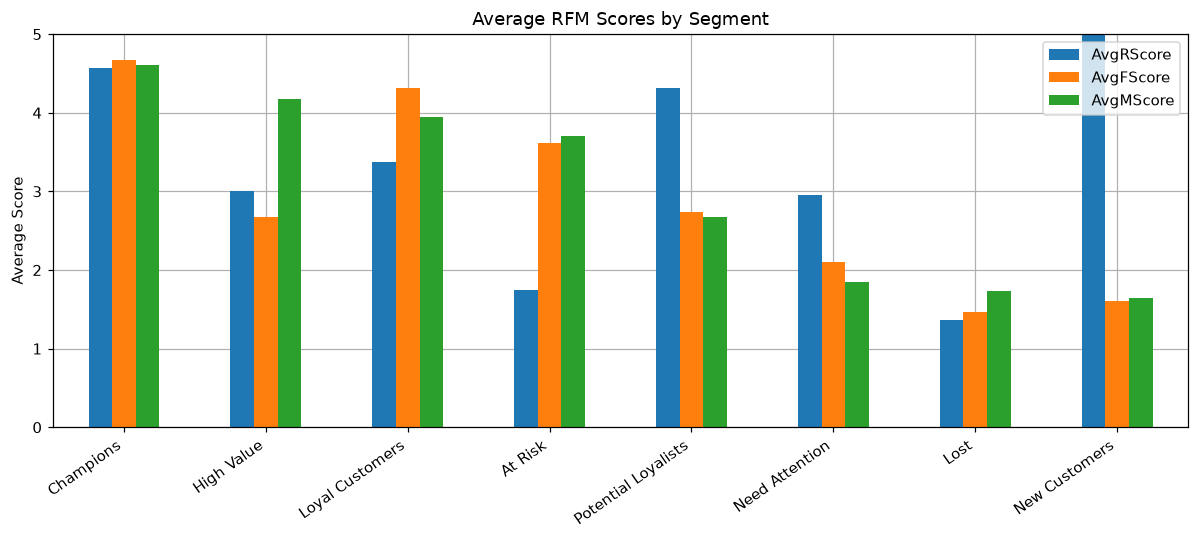

In [44]:
score_profile = segment_summary[[
    "AvgRScore", "AvgFScore", "AvgMScore"
]].sort_values("AvgMScore", ascending=False)

score_profile.plot(
    kind="bar",
    figsize=(11, 5)
)

plt.title("Average RFM Scores by Segment")
plt.xlabel("")
plt.ylabel("Average Score")
plt.ylim(0, 5)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

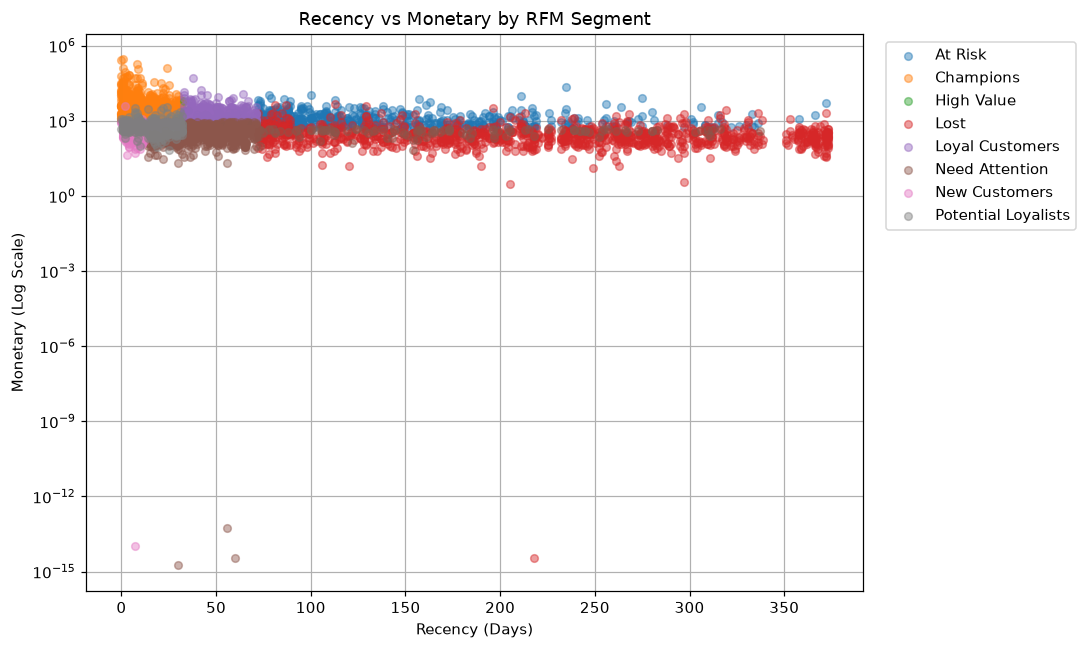

In [45]:
plt.figure(figsize=(10, 6))

for segment, group in rfm_scored.groupby("Segment"):
    plt.scatter(
        group["Recency"],
        group["Monetary"],
        alpha=0.45,
        s=25,
        label=segment
    )

plt.yscale("log")
plt.title("Recency vs Monetary by RFM Segment")
plt.xlabel("Recency (Days)")
plt.ylabel("Monetary (Log Scale)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# 35. RFM interpretation & business follow-up


In [46]:
largest_segment = segment_summary["Customers"].idxmax()
highest_value_segment = segment_summary["TotalMonetary"].idxmax()
most_recent_segment = segment_summary["AvgRecency"].idxmin()
most_frequent_segment = segment_summary["AvgFrequency"].idxmax()

at_risk_revenue = 0
if "At Risk" in segment_summary.index:
    at_risk_revenue = segment_summary.loc["At Risk", "TotalMonetary"]

rfm_insights = pd.DataFrame({
    "Insight": [
        f"Largest customer group: {largest_segment}.",
        f"Highest total customer value: {highest_value_segment}.",
        f"Most recently active group: {most_recent_segment}.",
        f"Highest average purchase frequency: {most_frequent_segment}.",
        f"Net value currently sitting in the At Risk group: {at_risk_revenue:,.2f}.",
        "Rule-based RFM segments remain a transparent benchmark alongside the broader clustering result."
    ],
    "Follow-up": [
        "Design campaigns that fit the needs of the largest customer base.",
        "Protect the segment contributing the most value.",
        "Use this segment to understand current product and timing preferences.",
        "Use cross-sell and loyalty tactics to protect repeat purchasing.",
        "Prioritize high-value win-back opportunities inside the At Risk segment.",
        "Use the rule-based profiles for finer campaign targeting and the K-Means clusters as a higher-level behavioral split."
    ]
})

display(rfm_insights)

,Insight,Follow-up
0,Largest customer group: Lost.,Design campaigns that fit the needs of the largest customer base.
1,Highest total customer value: Champions.,Protect the segment contributing the most value.
2,Most recently active group: New Customers.,Use this segment to understand current product and timing preferences.
3,Highest average purchase frequency: Champions.,Use cross-sell and loyalty tactics to protect repeat purchasing.
4,"Net value currently sitting in the At Risk group: 760,657.99.",Prioritize high-value win-back opportunities inside the At Risk segment.
5,Rule-based RFM segments remain a transparent benchmark alongside the broader clustering result.,Use the rule-based profiles for finer campaign targeting and the K-Means clusters as a higher-level behavioral split.


In [47]:
# Add the RFM labels to the wider customer feature table for later profiling.
customer_features = customer_features.merge(
    rfm_scored[[
        "CustomerID",
        "R_Score", "F_Score", "M_Score",
        "RFM_Score", "RFM_Total", "Segment"
    ]],
    on="CustomerID",
    how="left"
)

display(customer_features.head())

,CustomerID,FirstPurchase,LastPurchase,Frequency,GrossSales,Monetary,ReturnValue,ReturnRate,Recency,ActiveMonths,PurchaseSpanDays,AvgDaysBetweenOrders,AvgOrderValue,AvgBasketUnits,AvgUniqueProducts,BulkOrderRate,ProductVariety,CountryCount,MainCountry,IsUKCustomer,OneTimeBuyer,MonetaryNonPositive,R_Score,F_Score,M_Score,RFM_Score,RFM_Total,Segment
0,12347,2010-12-07 14:57:00,2011-12-07 15:52:00,7,"4,310.00","4,310.00",0.00,0.00,2,7,365,60.83,615.71,351.14,26.00,0.14,103.00,1,Iceland,0,0,0,5.00,5.00,5.00,555,15.00,Champions
1,12348,2010-12-16 19:09:00,2011-09-25 13:13:00,4,"1,797.24","1,797.24",0.00,0.00,75,4,282,94.00,449.31,583.00,5.75,0.50,21.00,1,Finland,0,0,0,2.00,4.00,4.00,244,10.00,At Risk
2,12349,2011-11-21 09:51:00,2011-11-21 09:51:00,1,"1,757.55","1,757.55",0.00,0.00,18,1,0,NaN,"1,757.55",630.00,72.00,1.00,72.00,1,Italy,0,1,0,4.00,2.00,4.00,424,10.00,Potential Loyalists
3,12350,2011-02-02 16:01:00,2011-02-02 16:01:00,1,334.40,334.40,0.00,0.00,310,1,0,NaN,334.40,196.00,16.00,0.00,16.00,1,Norway,0,1,0,1.00,2.00,2.00,122,5.00,Lost
4,12352,2011-02-16 12:33:00,2011-11-03 14:37:00,8,"2,506.04","1,545.41",960.63,0.38,36,4,260,37.14,237.96,75.14,11.00,0.00,57.00,1,Norway,0,0,0,3.00,5.00,4.00,354,12.00,Loyal Customers


In [48]:
# Final RFM validation.
assert rfm_scored["CustomerID"].is_unique
assert rfm_scored[["R_Score", "F_Score", "M_Score"]].notna().all().all()
assert rfm_scored["RFM_Score"].str.len().eq(3).all()
assert rfm_scored["Segment"].notna().all()

print("RFM customers:", len(rfm_scored))
print("Segments:", rfm_scored["Segment"].nunique())
print("Ready for unsupervised clustering and evaluation below.")

RFM customers: 4322
Segments: 8
Ready for unsupervised clustering and evaluation below.


# 36. Prepare RFM features for clustering

The clustering model uses only Recency, Frequency, and Monetary. CustomerID is an identifier, not a behavioral measurement. `log1p` reduces the influence of heavy right tails, then `StandardScaler` puts all three dimensions on comparable scales. The model-ready population excludes customers with non-positive net Monetary, whose value cannot be log-transformed meaningfully.

In [49]:
from sklearn.preprocessing import StandardScaler

cluster_features = rfm_ready[["Recency", "Frequency", "Monetary"]].copy()
assert cluster_features.notna().all().all()
assert (cluster_features >= 0).all().all()

rfm_log = np.log1p(cluster_features)
scaler = StandardScaler()
X_rfm = scaler.fit_transform(rfm_log)

print("Customers clustered:", len(X_rfm))
print("Features:", list(cluster_features.columns))
print("Scaled feature means:", np.round(X_rfm.mean(axis=0), 3))
print("Scaled feature standard deviations:", np.round(X_rfm.std(axis=0), 3))

Customers clustered: 4322
Features: ['Recency', 'Frequency', 'Monetary']
Scaled feature means: [ 0.  0. -0.]
Scaled feature standard deviations: [1. 1. 1.]


# 37. Compare K-Means cluster counts

WCSS (inertia) always falls as more clusters are added, so it is considered together with silhouette width rather than used alone. Silhouette is calculated on a fixed-size deterministic sample to keep the evaluation practical and comparable across candidate values of K.

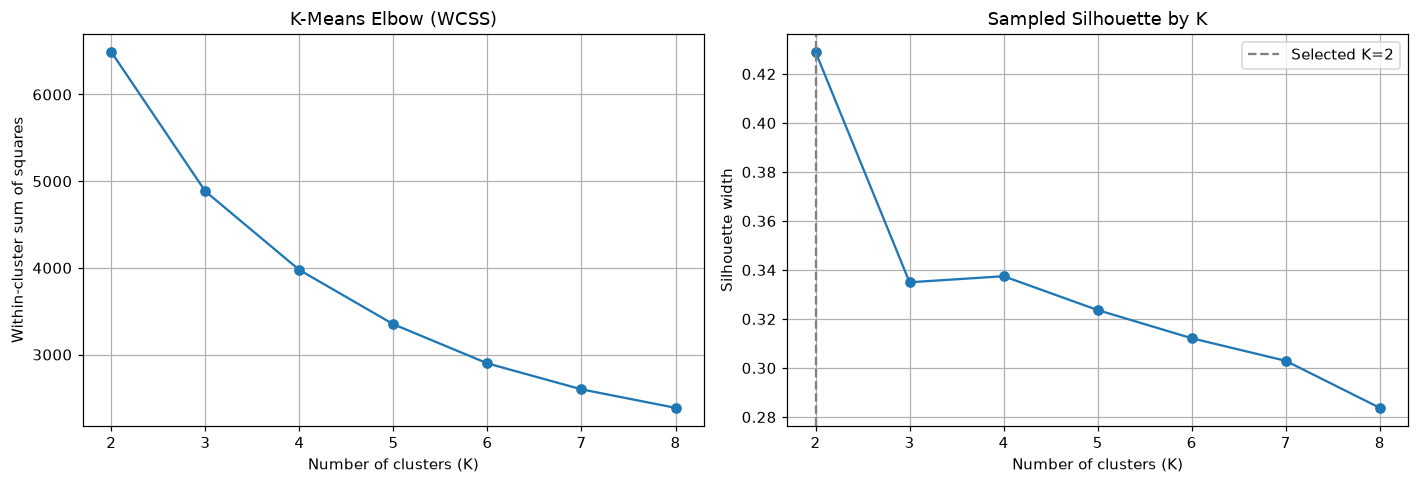

,Algorithm,Clusters,Inertia,Silhouette,NoiseShare_%
0,K-Means,2,"6,490.39",0.43,0.00
1,K-Means,3,"4,882.95",0.34,0.00
2,K-Means,4,"3,976.06",0.34,0.00
3,K-Means,5,"3,349.87",0.32,0.00
4,K-Means,6,"2,898.30",0.31,0.00
5,K-Means,7,"2,598.97",0.30,0.00
6,K-Means,8,"2,385.70",0.28,0.00


Selected K=2 by the highest sampled silhouette among K=2..8.


In [50]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = range(2, 9)
max_silhouette_sample = min(2000, len(X_rfm))
model_rows = []
kmeans_candidates = {}

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = model.fit_predict(X_rfm)
    sil = silhouette_score(
        X_rfm, labels, sample_size=max_silhouette_sample, random_state=42
    )
    kmeans_candidates[k] = model
    model_rows.append({
        "Algorithm": "K-Means",
        "Clusters": k,
        "Inertia": model.inertia_,
        "Silhouette": sil,
        "NoiseShare_%": 0.0
    })

kmeans_evaluation = pd.DataFrame(model_rows)
best_k = int(kmeans_evaluation.loc[kmeans_evaluation["Silhouette"].idxmax(), "Clusters"])
kmeans_model = kmeans_candidates[best_k]
kmeans_labels = kmeans_model.labels_

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(kmeans_evaluation["Clusters"], kmeans_evaluation["Inertia"], marker="o")
ax[0].set_title("K-Means Elbow (WCSS)")
ax[0].set_xlabel("Number of clusters (K)")
ax[0].set_ylabel("Within-cluster sum of squares")
ax[1].plot(kmeans_evaluation["Clusters"], kmeans_evaluation["Silhouette"], marker="o")
ax[1].axvline(best_k, linestyle="--", color="gray", label=f"Selected K={best_k}")
ax[1].set_title("Sampled Silhouette by K")
ax[1].set_xlabel("Number of clusters (K)")
ax[1].set_ylabel("Silhouette width")
ax[1].legend()
plt.tight_layout()
plt.show()

display(kmeans_evaluation.round(3))
print(f"Selected K={best_k} by the highest sampled silhouette among K=2..8.")

# 38. Compare hierarchical clustering and DBSCAN

Hierarchical clustering is evaluated on a reproducible customer sample because its memory and compute costs grow quickly. The dendrogram is shown on a smaller sample for readability. DBSCAN is assessed on the full scaled RFM set using neighborhood-distance quantiles; its noise share is reported explicitly, and silhouette excludes points DBSCAN classifies as noise.

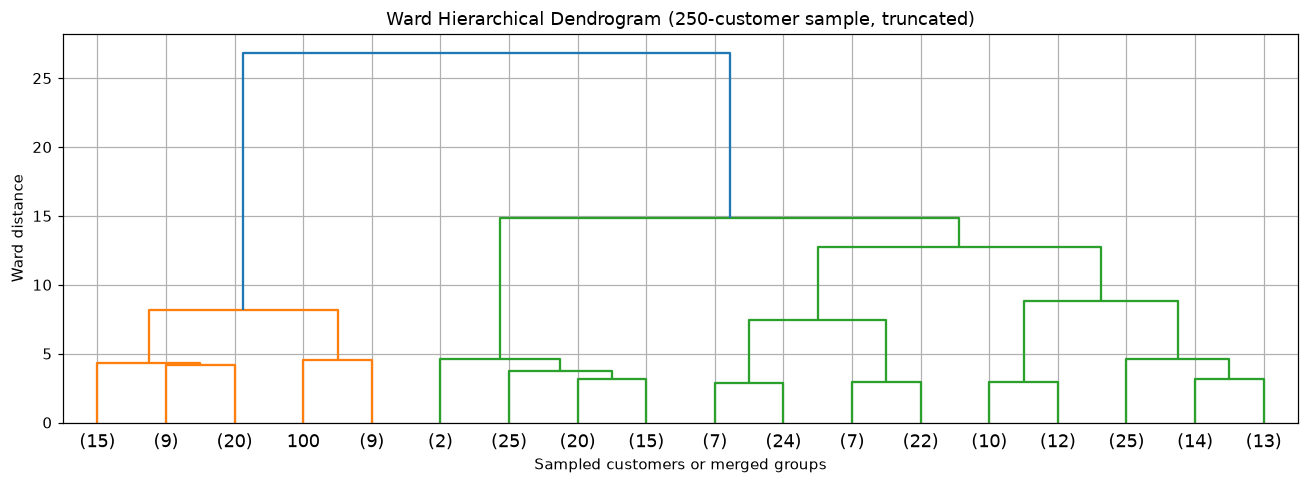

Hierarchical sample: 1,200 customers; sampled silhouette=0.334
DBSCAN parameter checks:


,Algorithm,Clusters,Inertia,Silhouette,NoiseShare_%,eps,min_samples
0,DBSCAN,4,NaN,0.14,8.81,0.32,10
1,DBSCAN,3,NaN,0.18,5.23,0.38,10
2,DBSCAN,2,NaN,0.29,2.36,0.50,10


Comparable model summary:


,Algorithm,Clusters,Inertia,Silhouette,NoiseShare_%
0,K-Means,2,"6,490.39",0.43,0.00
1,Hierarchical (Ward sample),2,NaN,0.33,0.00
2,DBSCAN,4,NaN,0.14,8.81
3,DBSCAN,3,NaN,0.18,5.23
4,DBSCAN,2,NaN,0.29,2.36


In [51]:
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import dendrogram, linkage

rng = np.random.default_rng(42)
hier_n = min(1200, len(X_rfm))
hier_idx = np.sort(rng.choice(len(X_rfm), size=hier_n, replace=False))
X_hier = X_rfm[hier_idx]
hierarchical = AgglomerativeClustering(n_clusters=best_k, linkage="ward")
hier_labels = hierarchical.fit_predict(X_hier)
hier_silhouette = silhouette_score(
    X_hier, hier_labels, sample_size=min(1200, hier_n), random_state=42
) if len(np.unique(hier_labels)) > 1 else np.nan

dendro_n = min(250, len(X_rfm))
dendro_idx = np.sort(rng.choice(len(X_rfm), size=dendro_n, replace=False))
Z = linkage(X_rfm[dendro_idx], method="ward")
plt.figure(figsize=(12, 4.5))
dendrogram(Z, truncate_mode="lastp", p=18, show_leaf_counts=True)
plt.title("Ward Hierarchical Dendrogram (250-customer sample, truncated)")
plt.xlabel("Sampled customers or merged groups")
plt.ylabel("Ward distance")
plt.tight_layout()
plt.show()

# Estimate useful eps values from each customer's 10th-neighbor distance.
min_samples = 10
neighbors = NearestNeighbors(n_neighbors=min_samples).fit(X_rfm)
distances, _ = neighbors.kneighbors(X_rfm)
k_distance = np.sort(distances[:, -1])
eps_values = np.quantile(k_distance, [0.85, 0.90, 0.95])
dbscan_rows = []
dbscan_candidates = {}
for eps in np.unique(np.round(eps_values, 4)):
    db = DBSCAN(eps=float(eps), min_samples=min_samples, n_jobs=-1)
    labels = db.fit_predict(X_rfm)
    non_noise = labels != -1
    cluster_count = len(set(labels[non_noise]))
    noise_share = 1 - non_noise.mean()
    valid_silhouette = np.nan
    if cluster_count >= 2 and non_noise.sum() > cluster_count:
        X_eval = X_rfm[non_noise]
        labels_eval = labels[non_noise]
        valid_silhouette = silhouette_score(
            X_eval, labels_eval,
            sample_size=min(2000, len(X_eval)), random_state=42
        )
    dbscan_candidates[float(eps)] = (db, labels)
    dbscan_rows.append({
        "Algorithm": "DBSCAN", "Clusters": cluster_count,
        "Inertia": np.nan, "Silhouette": valid_silhouette,
        "NoiseShare_%": noise_share * 100, "eps": float(eps),
        "min_samples": min_samples
    })

dbscan_evaluation = pd.DataFrame(dbscan_rows)
hierarchical_row = pd.DataFrame([{
    "Algorithm": "Hierarchical (Ward sample)", "Clusters": best_k,
    "Inertia": np.nan, "Silhouette": hier_silhouette,
    "NoiseShare_%": 0.0
}])
model_comparison = pd.concat([
    kmeans_evaluation[kmeans_evaluation["Clusters"] == best_k],
    hierarchical_row, dbscan_evaluation.drop(columns=["eps", "min_samples"], errors="ignore")
], ignore_index=True, sort=False)

print(f"Hierarchical sample: {hier_n:,} customers; sampled silhouette={hier_silhouette:.3f}")
print("DBSCAN parameter checks:")
display(dbscan_evaluation.round(3))
print("Comparable model summary:")
display(model_comparison.round(3))

# 39. Profile and translate K-Means clusters

The algorithmic labels are arbitrary numbers. This profile compares each cluster's median RFM values with the population medians, then assigns a descriptive label and a proportionate action. These are descriptive segments, not causal or predictive claims.

In [52]:
rfm_clustered = rfm_ready.copy()
rfm_clustered["Cluster"] = kmeans_labels

cluster_profile = rfm_clustered.groupby("Cluster").agg(
    Customers=("CustomerID", "nunique"),
    MedianRecency=("Recency", "median"),
    MedianFrequency=("Frequency", "median"),
    MedianMonetary=("Monetary", "median"),
    MeanRecency=("Recency", "mean"),
    MeanFrequency=("Frequency", "mean"),
    MeanMonetary=("Monetary", "mean"),
    TotalMonetary=("Monetary", "sum")
)
cluster_profile["CustomerShare_%"] = cluster_profile["Customers"] / len(rfm_clustered) * 100
cluster_profile["RevenueShare_%"] = cluster_profile["TotalMonetary"] / rfm_clustered["Monetary"].sum() * 100

medians = rfm_clustered[["Recency", "Frequency", "Monetary"]].median()
def describe_cluster(row):
    recent = row["MedianRecency"] <= medians["Recency"]
    frequent = row["MedianFrequency"] > medians["Frequency"]
    valuable = row["MedianMonetary"] > medians["Monetary"]
    if recent and frequent and valuable:
        return ("Recent high-value repeat", "Reward loyalty and cross-sell; avoid unnecessary blanket discounts.")
    if not recent and frequent and valuable:
        return ("At-risk high-value repeat", "Prioritize a personalized win-back and check for service or product issues.")
    if recent and frequent:
        return ("Recent repeat buyers", "Encourage repeat cadence with relevant recommendations and replenishment.")
    if frequent:
        return ("Lapsed repeat buyers", "Test a targeted reactivation message before investing in broad discounts.")
    if recent and valuable:
        return ("Recent high-spend occasional", "Follow up with complementary products and a second-purchase journey.")
    if valuable:
        return ("High-spend occasional / lapsed", "Review the latest purchase date and offer a relevant, low-friction return path.")
    if recent:
        return ("Recent developing buyers", "Use onboarding and a second-purchase prompt to build engagement.")
    return ("Low-engagement buyers", "Use low-cost reactivation only when expected value supports it.")

cluster_profile[["Profile", "RecommendedAction"]] = cluster_profile.apply(
    lambda row: pd.Series(describe_cluster(row)), axis=1
)
cluster_profile = cluster_profile.sort_values("TotalMonetary", ascending=False).round(2)
display(cluster_profile)

rfm_clustered = rfm_clustered.merge(
    cluster_profile[["Profile", "RecommendedAction"]], left_on="Cluster", right_index=True, how="left"
)
assert rfm_clustered["Cluster"].notna().all()
assert rfm_clustered["Profile"].notna().all()

,Customers,MedianRecency,MedianFrequency,MedianMonetary,MeanRecency,MeanFrequency,MeanMonetary,TotalMonetary,CustomerShare_%,RevenueShare_%,Profile,RecommendedAction
Cluster,,,,,,,,,,,,
0,1652,16.00,6.00,"2,024.70",25.05,8.49,"4,239.40","7,003,493.97",38.22,84.38,Recent high-value repeat,Reward loyalty and cross-sell; avoid unnecessary blanket discounts.
1,2670,95.00,1.00,355.72,133.19,1.68,485.41,"1,296,034.12",61.78,15.62,Low-engagement buyers,Use low-cost reactivation only when expected value supports it.


# 40. Cluster visualizations and action summary

The plots show cluster size and median RFM behavior in original business units. Monetary is displayed on a log scale because customer value remains strongly right-skewed even after it has been transformed for model fitting.

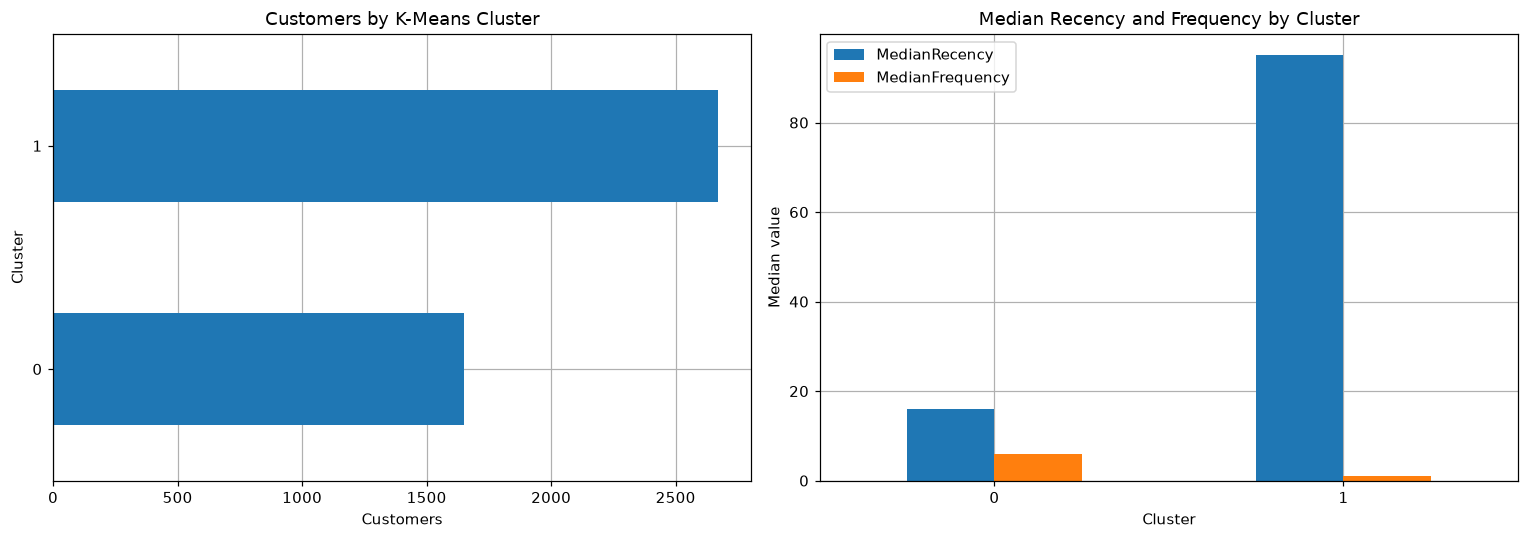

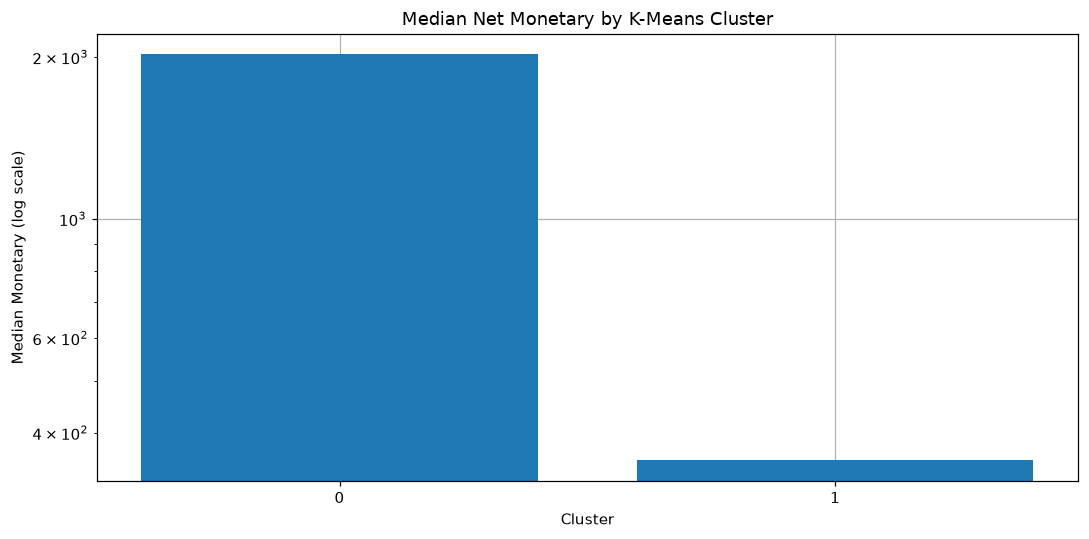

,Profile,Customers,CustomerShare_%,MedianRecency,MedianFrequency,MedianMonetary,RevenueShare_%,RecommendedAction
Cluster,,,,,,,,
0,Recent high-value repeat,1652,38.22,16.00,6.00,"2,024.70",84.38,Reward loyalty and cross-sell; avoid unnecessary blanket discounts.
1,Low-engagement buyers,2670,61.78,95.00,1.00,355.72,15.62,Use low-cost reactivation only when expected value supports it.


In [53]:
cluster_order = cluster_profile.sort_values("Customers").index.astype(str)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
cluster_profile.loc[cluster_order.astype(int), "Customers"].plot(kind="barh", ax=ax[0])
ax[0].set_title("Customers by K-Means Cluster")
ax[0].set_xlabel("Customers")
ax[0].set_ylabel("Cluster")

plot_profile = cluster_profile.sort_index()
plot_profile[["MedianRecency", "MedianFrequency"]].plot(kind="bar", ax=ax[1])
ax[1].set_title("Median Recency and Frequency by Cluster")
ax[1].set_xlabel("Cluster")
ax[1].set_ylabel("Median value")
ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.bar(cluster_profile.index.astype(str), cluster_profile["MedianMonetary"])
plt.yscale("log")
plt.title("Median Net Monetary by K-Means Cluster")
plt.xlabel("Cluster")
plt.ylabel("Median Monetary (log scale)")
plt.tight_layout()
plt.show()

display(cluster_profile[[
    "Profile", "Customers", "CustomerShare_%", "MedianRecency",
    "MedianFrequency", "MedianMonetary", "RevenueShare_%", "RecommendedAction"
]])

# 41. Business recommendations

Actions below are prioritized from observed cluster size, value, and engagement. They should be treated as testable campaign hypotheses; transaction history alone does not prove why a customer became inactive or whether an offer will change behavior.

In [54]:
priority_clusters = cluster_profile.sort_values("TotalMonetary", ascending=False)
print(f"Model choice: K-Means with K={best_k}, selected by highest sampled silhouette in the tested range.")
print(f"K-Means silhouette (sampled): {kmeans_evaluation.loc[kmeans_evaluation['Clusters'] == best_k, 'Silhouette'].iloc[0]:.3f}")
print(f"Hierarchical Ward silhouette (sample): {hier_silhouette:.3f}")

for cluster_id, row in priority_clusters.iterrows():
    print(
        f"Cluster {cluster_id} ({row['Profile']}): {int(row['Customers']):,} customers, "
        f"{row['RevenueShare_%']:.1f}% of positive net customer value. "
        f"Action: {row['RecommendedAction']}"
    )

print("\nDeployment checks: pilot actions on a holdout period, monitor repeat purchase and net margin, and avoid treating cluster membership as a churn prediction.")

Model choice: K-Means with K=2, selected by highest sampled silhouette in the tested range.
K-Means silhouette (sampled): 0.429
Hierarchical Ward silhouette (sample): 0.334
Cluster 0 (Recent high-value repeat): 1,652 customers, 84.4% of positive net customer value. Action: Reward loyalty and cross-sell; avoid unnecessary blanket discounts.
Cluster 1 (Low-engagement buyers): 2,670 customers, 15.6% of positive net customer value. Action: Use low-cost reactivation only when expected value supports it.

Deployment checks: pilot actions on a holdout period, monitor repeat purchase and net margin, and avoid treating cluster membership as a churn prediction.


# 42. Limitations and next steps

- The data covers a historical observation window ending in 2011; segments describe that period and should not be assumed to represent current customers.
- Customers without an ID remain useful in store-level analysis but are excluded from customer segmentation. Fourteen customers with non-positive net Monetary are retained in the customer feature table but excluded from log-based RFM clustering.
- Log transformation and standardization reduce scale and skew problems but do not remove all outlier influence. K-Means favors compact, roughly spherical groups and assigns every modeled customer to a cluster.
- The silhouette score is estimated on a fixed random sample; hierarchical clustering is intentionally evaluated on a sample for computational practicality. DBSCAN results depend on `eps` and `min_samples`, and no density-based result is forced if it mostly labels customers as noise or one cluster.
- The selected K is the highest sampled silhouette within K=2..8, considered alongside the elbow plot. This is a defensible baseline, not proof that the groups are uniquely correct. Validate stability across time windows, random samples, and business use cases.
- Recommended next steps: test cluster stability, validate segment definitions with stakeholders, run a controlled campaign pilot, and monitor incremental repeat revenue, return rates, and margin before scaling offers.

# 43. Final conclusion

In [55]:
print(
    f"The analysis turns {len(rfm_ready):,} identified customers with positive net value into "
    f"{best_k} broad K-Means groups using log-transformed, standardized Recency, Frequency, and Monetary. "
    f"The selected model's sampled silhouette is "
    f"{kmeans_evaluation.loc[kmeans_evaluation['Clusters'] == best_k, 'Silhouette'].iloc[0]:.3f}."
)
print(
    "Cluster 0 is a recent, higher-value repeat group; Cluster 1 is a larger, lower-engagement group. "
    "This two-group solution is a useful macro-level summary, not a replacement for the eight more "
    "granular rule-based RFM segments used for targeted campaign design. Validate the historical "
    "profiles on newer data and measure campaign impact with controlled tests before operational use."
)

The analysis turns 4,322 identified customers with positive net value into 2 broad K-Means groups using log-transformed, standardized Recency, Frequency, and Monetary. The selected model's sampled silhouette is 0.429.
Cluster 0 is a recent, higher-value repeat group; Cluster 1 is a larger, lower-engagement group. This two-group solution is a useful macro-level summary, not a replacement for the eight more granular rule-based RFM segments used for targeted campaign design. Validate the historical profiles on newer data and measure campaign impact with controlled tests before operational use.
